# Record fixes and frozen rival predictors: demo of `eval.py`

**Artifact:** `art_mgek9PfVBNbh`, iteration 5, Step 0 (evaluation, CPU only, no model is run).

This notebook runs the record-correction stage of the artifact's `eval.py`. The original code is split into cells and kept as written, with explanations between the steps. Every input is loaded from `mini_demo_data.json`.

### Background

The project studies which algorithm an instruction-tuned LLM writes for a coding task. Two examples: BFS or DFS for a grid path, Dijkstra or Bellman-Ford for weighted shortest paths. The main model is Qwen3-8B, and gemma-3-4b-it is a held-out model family. Two interventions are studied:
- a **prompt ban**, which forbids the model's default algorithm;
- **plan noise**, a push along a random direction in the hidden states at the prompt's task-specification tokens.

The question is whether these change the choice, and where the model lands when they do.

### What `eval.py` does

`eval.py` re-derives the numbers behind the iteration-4 review items from the row and result files of earlier artifacts:
- Every number gets a **provenance tag**: `RE-DERIVED` (recomputed from rows), `READ` (taken from a results file), `CARRIED` (from the record) or `NOT_COMPUTABLE`.
- Where the iteration-4 record states a value, the number also gets a **status** against fixed tolerances: `MATCH`, `CORRECTED` or `NEW` (no record value). The tolerances are: counts exact, rates 0.005, Hill-1 / log scores / correlations 0.01, intervals 0.02.
- Every fix is written as an exact `old_text -> new_text` replacement for the report, in `corrections.json`.

After that, `eval.py` launches separate scripts. They freeze eight rival task predictors by sha256 and score them, re-verify six quotes live, run an independent stdlib audit, and assemble `eval_out.json`.

### What this notebook runs

- **Runs:** everything `eval.py` computes itself. That is items (0a) to (0e), (0g) and (0h), plus the iteration-1 base compositions. The inputs are the 53 dependency files the stage reads, stored in `mini_demo_data.json`, one example per file. Rows and fields that `eval.py` never touches were dropped, which shrinks 77.7 MB to 4.5 MB. The re-derived numbers are therefore the same as on the full files.
- **Does not run:** the scripts `eval.py` starts as subprocesses: `rivals/compute_rivals.py`, `rivals/score_rivals.py`, `quotes/verify_quotes.py` (item 0f, live web), `audit/rederive.py` and `src/assemble.py`. They are separate files in the artifact repository.

**Results the artifact reports.** The last cells check these against this notebook's own output.
- **(0a)** Gemma held-out test, "movability predicts ban compliance": balanced accuracy 0.739, Fisher p 0.235, Spearman 0.537, so **INCONCLUSIVE**. Under the default-drop sensitivity: BA 0.568, p 1.0, Spearman 0.391, so **DISCONFIRMED**.
- **(0b)** Correct programs off the default when the noise hits the read position (S1), the condition sentence (S2) or the late blocks (S5): 0 of 526, 0 of 527 and 6 of 521. On find duplicate, generated-token noise beats the plan site in paired flips 12:0 (exact McNemar p 0.000488).
- **(0c)** Mean landing log score: push forecast −0.761 against association −3.115 on the 3 events where the push forecast exists. Over all 5 events, with an undefined forecast scored as uniform: −1.366 against −3.462.
- **Provenance:** 186 values MATCH, 1 is CORRECTED, 15 are NEW, 4 are CARRIED.

### Terms

| Term | Meaning |
|---|---|
| twin | the control prompt; the task's **default** D is the most frequent algorithm among the twin's correct programs |
| ban | the prompt forbids the default |
| catalogue | the bench's list of known algorithms for a task; *other* = a program that matches none |
| E_t (movability) | share of the plan-noise directions run on a task whose escape from the default was confirmed |
| A_t | catalogue-only avoidance: share of ban-arm programs that use a catalogue algorithm other than D |
| drop | default-share drop: the default's share under the twin minus its share under the ban |
| Hill-1 | exp(Shannon entropy) of the algorithm mix of correct programs, rarefied to 25 programs |
| alpha | the noise dose in ban units; one ban unit is the hidden-state displacement the ban itself causes |
| S0 … S5 | where the noise is added: S0 plan site (task-specification states, blocks 12–23), S4 the same states at blocks 0–11, S1 read position, S2 condition sentence, S3 generated tokens 1–32, S5 late blocks; S1E/S2E are S1/S2 at matched energy |
| CRN pair | two arms that ran on the same random-number slot (common random numbers) |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (eval.py's logger) — NOT pre-installed on Colab, always install (the artifact pins 0.7.3)
_pip('loguru==0.7.3')

# numpy, scipy (statistics), matplotlib, pandas (results cells) — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- eval.py (original import block) ---
import argparse
import csv
import json
import math
import re
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger

# --- src/stats_util.py and src/io_util.py (both inlined as cells below) ---
import hashlib
import itertools
import os
from typing import Callable, Iterable, Sequence

from scipy import stats

# --- notebook only: data loading, row copies, the `su` namespace, results tables and the figure ---
import copy
import textwrap
import types
from pathlib import PurePosixPath

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-5/evaluation-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

# One example per dependency file that eval.py's corrections stage reads ('<artifact_id>:<relative path>')
exs = data["datasets"][0]["examples"]
print(f"{len(exs)} input files from {len(data['metadata']['dependencies'])} dependency artifacts, "
      f"{data['metadata']['n_rows_kept_total']:,} rows (the original files total "
      f"{data['metadata']['original_bytes_total'] / 1e6:.1f} MB)")
for ex in exs:
    if ex.get("reduced"):
        print(f"  {ex['source']}: {ex['n_rows_kept']:,} of {ex['n_rows_original']:,} rows kept, fields {ex['fields_kept']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
53 input files from 7 dependency artifacts, 23,741 rows (the original files total 77.7 MB)
  art_k6nzFCDLOjQP:data/samples.jsonl: 2,400 of 10,730 rows kept, fields ['task', 'stage', 'arm', 'label', 'passed']
  art_Cx9JOh8soBw7:data/samples.jsonl: 3,960 of 4,752 rows kept, fields ['task', 'arm', 'site', 'slot', 'label', 'passed', 'code']
  art_SHaWv77P1XCI:data/labels.jsonl: 10,520 of 13,500 rows kept, fields ['task', 'arm', 'label', 'passed']
  art_mWn-MQEnNelg:data/samples.jsonl: 5,200 of 10,100 rows kept, fields ['task', 'arm', 'label', 'passed', 'crn_key']
  art_Yu6GN6pLxW8f:data/raw_thinking.jsonl: 140 of 140 rows kept, fields ['temperature', 'top_k']
  art_HF8nK8B_Lqyy:runs/labelled_base_chat__baseline.jsonl: 600 of 600 rows kept, fields ['task', 'label', 'passed']
  art_HF8nK8B_Lqyy:runs/labelled_base_tf__baseline.jsonl: 600 of 600 rows kept, fields ['task', 'label', 'passed']


## Configuration

The only tunable parameters of `eval.py` are Monte Carlo sizes in its statistics module. They affect only the bootstrap intervals, the permutation p-values and the (0a) placebo summary. Every count, rate, point estimate and exact test is the same at any setting.

This notebook keeps the artifact's original values: `N_BOOT = 10_000` bootstrap replicates, `N_PERM = 200_000` permutation draws and `N_PLACEBO = 1000` placebo draws. With them, the corrections stage takes about 10 s on a CPU, and all cells together about 22 s, the package install included. With 10 / 10 / 10 the stage takes under a second, and only the Monte Carlo quantities change.

`OUTPUT_DIR` is where `eval.py` writes its outputs: `tables/*.csv`, `results/*.json`, `corrections.json`, `ids.json` and `logs/eval.log`.

**Note:** if you change a value, re-run the notebook from this cell. The statistics cell binds `N_BOOT` and `N_PERM` as default arguments.

In [5]:
# Monte Carlo sizes: the only tunable parameters (src/stats_util.py and the (0a) placebo loop of eval.py).
# These are the artifact's original values. Smaller ones (e.g. 10 / 10 / 10) run in under a second and change only the
# Monte Carlo quantities: bootstrap intervals, permutation p-values and the placebo mean.
N_BOOT = 10_000     # bootstrap replicates (95% percentile intervals)
N_PERM = 200_000    # Monte Carlo permutation draws (Spearman p-values)
N_PLACEBO = 1000    # (0a) placebo draws, E_t permuted across tasks

OUTPUT_DIR = "eval_outputs"  # eval.py's tables/, results/, logs/, corrections.json and ids.json are written here

## Statistics helpers (`src/stats_util.py`)

`eval.py` imports this module as `su`. It holds:
- exact rarefied Hill-1 diversity, an exact expectation over subsamples drawn without replacement;
- a Spearman correlation with a Monte Carlo permutation p-value;
- Kendall's tau-b;
- bootstrap percentile intervals;
- an exact AUC with an enumeration p-value;
- Holm adjustment, balanced accuracy, Fisher's exact test, the exact McNemar test, the modal label and quantiles.

The code is copied unchanged, with two exceptions. `N_BOOT` and `N_PERM` come from the config cell. A `su` namespace at the end keeps every `su.<name>` call in `eval.py` as written.

In [6]:
"""Statistics shared by eval.py, rivals/compute_rivals.py and rivals/score_rivals.py (NOT by audit/rederive.py,
which re-implements everything with the standard library only).

Conventions (plan PART 0.5-0.6): numpy default_rng(20261021); bootstrap 10,000 replicates (percentile intervals);
permutation tests 200,000 Monte Carlo draws with the Monte Carlo SE; exact enumeration where feasible.
"""
# src/stats_util.py (its imports are in the imports cell)

SEED = 20261021
# N_BOOT = 10_000   original values; in this notebook N_BOOT and N_PERM are set in the config cell
# N_PERM = 200_000
NOT_ALT = ("other", "invalid", "disputed", "unknown", "unlabelled", None, "None", "")


# ------------------------------------------------------------------------------------------------ diversity
def hill1_raw(counts: dict[str, int]) -> float | None:
    c = np.array([v for v in counts.values() if v > 0], float)
    if c.sum() <= 0:
        return None
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def _compositions(caps: list[int], total: int):
    """All vectors k with 0 <= k_i <= caps_i and sum k = total."""
    if len(caps) == 1:
        if total <= caps[0]:
            yield (total,)
        return
    rest = sum(caps[1:])
    for k in range(max(0, total - rest), min(caps[0], total) + 1):
        for tail in _compositions(caps[1:], total - k):
            yield (k,) + tail


def hill1_rarefied(counts: dict[str, int], depth: int = 25) -> dict[str, Any]:
    """Exact expected Hill-1 (exp Shannon) of a subsample of size `depth` drawn WITHOUT replacement (multivariate
    hypergeometric enumeration; the run's Monte-Carlo estimator has the same expectation).  Depth falls back to the
    number of programs when fewer are available (flagged)."""
    cs = [int(v) for v in counts.values() if v > 0]
    n = sum(cs)
    if n == 0:
        return {"hill": None, "depth": 0, "flag": "no programs"}
    d = min(depth, n)
    flag = None if d == depth else f"own depth {d}"
    if len(cs) == 1:
        return {"hill": 1.0, "depth": d, "flag": flag}
    log_denom = math.lgamma(n + 1) - math.lgamma(d + 1) - math.lgamma(n - d + 1)
    lg = [[math.lgamma(c + 1) - math.lgamma(k + 1) - math.lgamma(c - k + 1) for k in range(c + 1)] for c in cs]
    tot = 0.0
    for comp in _compositions(cs, d):
        lp = sum(lg[i][k] for i, k in enumerate(comp)) - log_denom
        h = -sum((k / d) * math.log(k / d) for k in comp if k > 0)
        tot += math.exp(lp) * math.exp(h)
    return {"hill": float(tot), "depth": d, "flag": flag}


# ------------------------------------------------------------------------------------------------ correlation
def ranks(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float | None:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return None
    return float(np.corrcoef(ranks(x), ranks(y))[0, 1])


def perm_spearman(x: Sequence[float], y: Sequence[float], n_perm: int = N_PERM, seed: int = SEED,
                  chunk: int = 20_000) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = spearman(x, y)
    if rho is None:
        return {"rho": None, "p_two_sided": None, "p_one_sided_ge": None, "mc_se_two_sided": None, "n": len(x),
                "n_perm": n_perm, "note": "constant input or n < 3"}
    rx, ry = ranks(x), ranks(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    ge_abs = ge = 0
    done = 0
    while done < n_perm:
        m = min(chunk, n_perm - done)
        perm = np.argsort(rng.random((m, len(x))), axis=1)
        rp = (rx[None, :] * ry[perm]).mean(1)
        ge_abs += int(np.sum(np.abs(rp) >= abs(rho) - 1e-12))
        ge += int(np.sum(rp >= rho - 1e-12))
        done += m
    p2 = (ge_abs + 1) / (n_perm + 1)
    p1 = (ge + 1) / (n_perm + 1)
    return {"rho": rho, "p_two_sided": p2, "p_one_sided_ge": p1, "mc_se_two_sided": math.sqrt(p2 * (1 - p2) / n_perm),
            "n": len(x), "n_perm": n_perm}


def kendall_b(x: Sequence[float], y: Sequence[float]) -> float | None:
    if len(set(x)) < 2 or len(set(y)) < 2:
        return None
    return float(stats.kendalltau(x, y, variant="b").statistic)


def boot_spearman(x: Sequence[float], y: Sequence[float], n_boot: int = N_BOOT, seed: int = SEED) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rng = np.random.default_rng(seed + 7)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        r = spearman(x[idx], y[idx])
        if r is not None:
            vals.append(r)
    if not vals:
        return {"ci95": None, "n_valid": 0}
    return {"ci95": [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))], "n_valid": len(vals)}


def partial_spearman(x: Sequence[float], y: Sequence[float], z: np.ndarray | Sequence[float]) -> float | None:
    """Spearman correlation of x and y after removing (linear in ranks) one or more covariates z."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    z = np.asarray(z, float)
    if z.ndim == 1:
        z = z[:, None]
    if len(x) < 4 or np.std(x) == 0 or np.std(y) == 0:
        return None
    rz = np.column_stack([ranks(z[:, j]) for j in range(z.shape[1]) if np.std(z[:, j]) > 0] or [np.zeros(len(x))])
    X = np.column_stack([np.ones(len(x)), rz])
    rx, ry = ranks(x), ranks(y)
    ex = rx - X @ np.linalg.lstsq(X, rx, rcond=None)[0]
    ey = ry - X @ np.linalg.lstsq(X, ry, rcond=None)[0]
    if np.std(ex) < 1e-12 or np.std(ey) < 1e-12:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def auc_exact(scores: Sequence[float], labels: Sequence[int]) -> dict[str, Any]:
    """AUC = P(score_pos > score_neg) + 0.5 P(tie); exact two-sided rank-sum p by enumerating every assignment of
    the observed number of positives to the units (C(15,5) = 3,003 splits for the full panel)."""
    s = np.asarray(scores, float)
    lab = np.asarray(labels, int)
    npos, n = int(lab.sum()), len(lab)
    if npos == 0 or npos == n:
        return {"auc": None, "p_exact_two_sided": None, "n_splits": 0}

    def auc_of(pos_idx: tuple[int, ...]) -> float:
        m = np.zeros(n, bool)
        m[list(pos_idx)] = True
        a, b = s[m], s[~m]
        gt = (a[:, None] > b[None, :]).sum()
        eq = (a[:, None] == b[None, :]).sum()
        return float((gt + 0.5 * eq) / (len(a) * len(b)))

    obs = auc_of(tuple(np.flatnonzero(lab)))
    null = [auc_of(c) for c in itertools.combinations(range(n), npos)]
    dev = abs(obs - 0.5)
    p = float(np.mean([abs(v - 0.5) >= dev - 1e-12 for v in null]))
    return {"auc": obs, "p_exact_two_sided": p, "n_splits": len(null)}


def holm(ps: dict[str, float | None]) -> dict[str, float | None]:
    items = sorted([(k, v) for k, v in ps.items() if v is not None], key=lambda kv: kv[1])
    m = len(items)
    out: dict[str, float | None] = {k: None for k in ps}
    run = 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


# ------------------------------------------------------------------------------------------------ classification
def balanced_accuracy(pred: Sequence[int], obs: Sequence[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    pos, neg = obs == 1, obs == 0
    out = {"n_pos": int(pos.sum()), "n_neg": int(neg.sum()), "n_pred_pos": int(pred.sum())}
    if pos.sum() == 0 or neg.sum() == 0:
        out.update(BA=None, TPR=None, TNR=None)
        return out
    tpr = float((pred[pos] == 1).mean())
    tnr = float((pred[neg] == 0).mean())
    out.update(BA=(tpr + tnr) / 2, TPR=tpr, TNR=tnr)
    return out


def fisher(pred: Sequence[int], obs: Sequence[int]) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    tab = [[int(((pred == 1) & (obs == 1)).sum()), int(((pred == 1) & (obs == 0)).sum())],
           [int(((pred == 0) & (obs == 1)).sum()), int(((pred == 0) & (obs == 0)).sum())]]
    if pred.min() == pred.max() or obs.min() == obs.max():
        return {"table": tab, "p_two_sided": 1.0, "note": "degenerate margin"}
    return {"table": tab, "p_two_sided": float(stats.fisher_exact(tab, alternative="two-sided").pvalue)}


def boot_ba(pred: Sequence[int], obs: Sequence[int], n_boot: int = N_BOOT, seed: int = SEED) -> dict[str, Any]:
    pred, obs = np.asarray(pred, int), np.asarray(obs, int)
    rng = np.random.default_rng(seed + 11)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(pred), len(pred))
        r = balanced_accuracy(pred[idx], obs[idx])["BA"]
        if r is not None:
            vals.append(r)
    if not vals:
        return {"ci95": None, "n_valid": 0}
    return {"ci95": [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))], "n_valid": len(vals)}


def mcnemar_exact(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * stats.binom.cdf(min(b, c), n, 0.5)))


def modal(counter: Counter | dict) -> tuple[str | None, int]:
    if not counter:
        return None, 0
    m = max(counter.values())
    best = sorted(k for k, v in counter.items() if v == m)
    return best[0], m


def quantiles(vals: Iterable[float]) -> dict[str, float | None]:
    v = np.asarray([x for x in vals if x is not None], float)
    if len(v) == 0:
        return {"min": None, "q25": None, "median": None, "q75": None, "max": None, "n": 0}
    return {"min": float(v.min()), "q25": float(np.quantile(v, 0.25)), "median": float(np.median(v)),
            "q75": float(np.quantile(v, 0.75)), "max": float(v.max()), "n": int(len(v))}


# notebook: eval.py uses this module as `su` (import stats_util as su); the namespace keeps those calls unchanged
su = types.SimpleNamespace(
    SEED=SEED, N_BOOT=N_BOOT, N_PERM=N_PERM, NOT_ALT=NOT_ALT, hill1_raw=hill1_raw, _compositions=_compositions,
    hill1_rarefied=hill1_rarefied, ranks=ranks, spearman=spearman, perm_spearman=perm_spearman, kendall_b=kendall_b,
    boot_spearman=boot_spearman, partial_spearman=partial_spearman, auc_exact=auc_exact, holm=holm,
    balanced_accuracy=balanced_accuracy, fisher=fisher, boot_ba=boot_ba, mcnemar_exact=mcnemar_exact, modal=modal,
    quantiles=quantiles)

## Inputs and provenance records (`src/io_util.py`)

- `Inputs` is the single entry point for dependency files. It resolves a file and records it in a sha256 manifest. Each value cites its source as `'<artifact_id>:<path>'`.
- `val()` builds one provenance record. It compares the value with the record value under the tolerance for its kind: `count` exact, `rate` 0.005, `stat` 0.01, `interval` 0.02. It returns the status `MATCH` / `CORRECTED` / `NEW` / `CARRIED` / `NOT_COMPUTABLE`.

**Notebook change:** `Inputs` reads each file from the loaded `data` (dict `FILES`), not from the disk.
- The manifest records the sha256 and size of the original dependency file. `build_mini_demo_data.py` checked each one against the hash the artifact recorded.
- `json()` and `jsonl()` return fresh copies, just as re-reading a file would.
- `jsonl(..., must_contain=...)` keeps the original substring filter, applied to the row's JSON text.

In [7]:
"""Dependency paths, hashed input manifest and provenance records (plan PART 0.1-0.4)."""
# src/io_util.py (its imports are in the imports cell)

WS = Path.cwd()  # notebook: there is no __file__ (io_util: Path(__file__).resolve().parent.parent); no folder is opened
# Dependencies are read in place, read-only.  In the published repository each dependency artifact is a sibling folder
# of this one, named by its artifact id: <AII_DEPS_ROOT>/<artifact_id>, with AII_DEPS_ROOT defaulting to the parent
# folder of this workspace.  A single dependency can be pointed elsewhere with AII_DEP_<artifact_id> (non-alphanumeric
# characters of the id replaced by '_', e.g. AII_DEP_art_mWn_MQEnNelg).
DEPS_ROOT = Path(os.environ.get("AII_DEPS_ROOT", str(WS.parent)))
DEP_IDS: dict[str, str] = {
    "exp23": "art_k6nzFCDLOjQP",  # held-out family (gemma-3-4b-it), iteration 4
    "exp20": "art_Cx9JOh8soBw7",  # site experiment, iteration 4
    "exp22": "art_SHaWv77P1XCI",  # plan subspace / escape fractions, iteration 4
    "exp19": "art_mWn-MQEnNelg",  # plan noise knob table, iteration 4
    "exp21": "art_Yu6GN6pLxW8f",  # same-seed temperature vs plan noise, iteration 4
    "exp5": "art_HF8nK8B_Lqyy",   # iteration-1 base-model data (run 4VFKidE1bxPG)
    "bench": "art_0ndRfWKBWclR",  # iteration-2 coding bench
    "src": "art_j3Rm_lr2nzR6",    # iteration-1 source data (run 4VFKidE1bxPG)
}


def dep_dir(art_id: str) -> Path:
    return Path(os.environ.get("AII_DEP_" + re.sub(r"\W", "_", art_id), str(DEPS_ROOT / art_id)))


DEPS: dict[str, tuple[str, Path]] = {k: (a, dep_dir(a)) for k, a in DEP_IDS.items()}
TOL = {"count": 0.0, "rate": 0.005, "stat": 0.01, "interval": 0.02}
TASKS = ["T1", "T2", "T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R2", "R3", "R6"]
NAMES = {"T1": "grid path", "T2": "weighted shortest path", "T03": "kth smallest", "T04": "substring search",
         "T05": "two sum", "T06": "find duplicate", "T08": "Fibonacci", "T10": "connected components",
         "T11": "longest increasing subsequence", "T13": "merge intervals", "T14": "top-k frequent",
         "R1": "non-overlapping intervals", "R2": "cycle detection", "R3": "topological order",
         "R6": "first and last position"}

# notebook: every dependency file comes from the loaded `data` (one example per file, keyed '<artifact_id>:<path>')
FILES: dict[str, dict[str, Any]] = {ex["source"]: ex for ex in data["datasets"][0]["examples"]}


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def as_bool(v: Any) -> bool:
    return v is True or v == "True" or v == "true" or v == 1


class Inputs:
    """Every dependency file read goes through here: path resolution, sha256 manifest, a 'source' string."""

    def __init__(self, log: Callable[[str], None] | None = None, forbidden: tuple[str, ...] = ()):
        self.manifest: dict[str, dict[str, Any]] = {}
        self.log = log
        self.forbidden = forbidden

    def path(self, dep: str, rel: str) -> dict[str, Any]:
        art, root = DEPS[dep]
        # p = root / rel   (notebook: the file is looked up in FILES instead of on disk, and that entry is returned)
        src = f"{art}:{rel}"
        for f in self.forbidden:
            if f in src:
                raise PermissionError(f"forbidden input for this script: {src}")
        if src not in self.manifest:
            if src not in FILES:  # io_util: if not p.exists()
                self.manifest[src] = {"exists": False, "abs_dep": dep}
                raise FileNotFoundError(src)
            # sha256 and size of the ORIGINAL dependency file (io_util: sha256_file(p), p.stat().st_size)
            self.manifest[src] = {"exists": True, "sha256": FILES[src]["original_sha256"],
                                  "bytes": FILES[src]["original_bytes"], "dep": dep}
            if self.log:
                self.log(f"open {src}")
        return FILES[src]

    def src(self, dep: str, rel: str) -> str:
        return f"{DEPS[dep][0]}:{rel}"

    def json(self, dep: str, rel: str) -> Any:
        return copy.deepcopy(self.path(dep, rel)["content"])  # io_util: json.loads(self.path(dep, rel).read_text())

    def jsonl(self, dep: str, rel: str, must_contain: str | None = None) -> list[dict[str, Any]]:
        out = []
        for x in self.path(dep, rel)["content"]:  # io_util: for ln in <the file's lines>; json.loads(ln)
            if must_contain is not None and must_contain not in json.dumps(x):
                continue
            out.append(copy.deepcopy(x))  # a fresh copy, as from re-reading the file (sec_0b relabels rows in place)
        return out


def close(a: float | None, b: float | None, kind: str) -> bool | None:
    if a is None or b is None:
        return None
    return abs(float(a) - float(b)) <= TOL[kind] + 1e-12


def val(name: str, value: Any, tag: str, source: str, record: Any = None, kind: str = "stat",
        note: str | None = None) -> dict[str, Any]:
    """One provenance record.  status: MATCH / CORRECTED (outside tolerance) / NEW (no record value) / CARRIED /
    NOT_COMPUTABLE."""
    if tag == "CARRIED":
        status = "CARRIED"
    elif tag == "NOT_COMPUTABLE" or value is None:
        status = "NOT_COMPUTABLE"
    elif record is None:
        status = "NEW"
    elif isinstance(value, (int, float)) and isinstance(record, (int, float)):
        status = "MATCH" if close(value, record, kind) else "CORRECTED"
    elif isinstance(value, (list, tuple)) and isinstance(record, (list, tuple)) and len(value) == len(record) and \
            all(isinstance(x, (int, float)) for x in list(value) + list(record)):
        status = "MATCH" if all(close(a, b, kind) for a, b in zip(value, record)) else "CORRECTED"
    else:
        status = "MATCH" if value == record else "CORRECTED"
    out = {"name": name, "record_value": record, "value": value, "tag": tag, "source": source, "status": status,
           "tolerance": kind}
    if note:
        out["note"] = note
    return out


def r(x: Any, nd: int = 3) -> Any:
    if isinstance(x, float):
        return round(x, nd)
    if isinstance(x, list):
        return [r(v, nd) for v in x]
    if isinstance(x, dict):
        return {k: r(v, nd) for k, v in x.items()}
    return x

## `eval.py`: setup and helpers

This cell holds the logger (to stdout and `logs/eval.log`) and the shared accumulators: `CORR` collects the correction entries and `METRICS` the per-section metrics. It also defines four small helpers:
- `entry()` adds one `old_text -> new_text` correction with its provenance values, marked `iteration-5 correction`;
- `write_csv()` writes a table;
- `bench_catalogue()` reads each bench task's list of known algorithm modes from its `spec.json`;
- `defines_solve()` implements exp20's validity rule D13: a program that does not define `solve` is invalid.

**Notebook changes:** outputs go to `OUTPUT_DIR`, and the bench task folders are listed from the data instead of the bench directory.

In [8]:
"""Iteration-5 Step 0 (CPU only): fix the record (items 0a-0h) and freeze + score ban-free rival task predictors (0i).

Run:  .venv/bin/python eval.py            (full pipeline: corrections -> rivals freeze -> rival scoring -> assembly)
      .venv/bin/python eval.py --assemble (re-assemble eval_out.json from existing stage outputs, e.g. after audit)

Every number carries a provenance tag (RE-DERIVED / READ / CARRIED / RE-VERIFIED / NOT_COMPUTABLE) and, where the
iteration-4 record states a value, a status against the plan's tolerances (counts exact; rates 0.005; Hill-1, log
scores, correlations 0.01; intervals 0.02).  Sources are cited as '<artifact_id>:<relative path>'.
"""
# eval.py (its imports are in the imports cell)

WS = Path(OUTPUT_DIR).resolve()  # notebook: outputs go to OUTPUT_DIR (eval.py: WS = Path(__file__).resolve().parent)
WS.mkdir(parents=True, exist_ok=True)
# eval.py: sys.path.insert(0, str(WS / "src")); from io_util import DEPS, NAMES, TASKS, Inputs, as_bool, r, val;
#          import stats_util as su   -> notebook: both modules are the two cells above

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(WS / "logs").mkdir(exist_ok=True)
logger.add(WS / "logs" / "eval.log", rotation="30 MB", level="DEBUG")

MARK = "iteration-5 correction"
NOT_OFF = ("invalid", "disputed")
BAD = ("other", "invalid", "disputed", "unknown", "None", None, "")
CORR: list[dict[str, Any]] = []
METRICS: dict[str, Any] = {}
TABLES = WS / "tables"
RESULTS = WS / "results"
# notebook: the bench task folders (bench/<task>/spec.json) are listed from the loaded data, not from the disk
BENCH_DIRS = sorted({PurePosixPath(s.split(":", 1)[1]).parent for s in FILES
                     if s.startswith(DEPS["bench"][0] + ":bench/") and s.endswith("/spec.json")})


def entry(item: str, location: str, old: str, new: str, values: list[dict[str, Any]], **extra: Any) -> dict[str, Any]:
    e = {"item": item, "report_location": location, "old_text": old, "new_text": new, "values": values, "marker": MARK}
    e.update(extra)
    CORR.append(e)
    return e


def write_csv(name: str, rows: list[dict[str, Any]]) -> None:
    TABLES.mkdir(exist_ok=True)
    if not rows:
        rows = [{"note": "no rows"}]
    keys: list[str] = []
    for row in rows:
        for k in row:
            if k not in keys:
                keys.append(k)
    with (TABLES / name).open("w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=keys)
        w.writeheader()
        for row in rows:
            w.writerow({k: (json.dumps(v) if isinstance(v, (dict, list)) else v) for k, v in row.items()})


def fmt(x: Any, nd: int = 2) -> str:
    if x is None:
        return "NA"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)


def bench_catalogue(I: Inputs) -> dict[str, list[str]]:
    cat = {}
    # root = DEPS["bench"][1] / "bench"   (notebook: BENCH_DIRS lists the task folders)
    for td in BENCH_DIRS:  # eval.py: sorted(p for p in root.iterdir() if p.is_dir() and (p / "spec.json").exists())
        t = td.name.split("_")[0]
        spec = I.json("bench", f"bench/{td.name}/spec.json")
        cat[t] = [c["mode"] for c in spec["catalogue"]]
    cat["T1"] = ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"]
    cat["T2"] = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]
    return cat


def defines_solve(code: Any) -> bool:
    if not code or code == "None":
        return False
    try:
        tree = __import__("ast").parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, __import__("ast").FunctionDef) and n.name == "solve" for n in __import__("ast").walk(tree))

## (0a) Held-out verdict per measure (Gemma, exp23)

This item tests whether movability predicts ban compliance in a held-out model family (gemma-3-4b-it, 15 tasks). For each task it computes:
- **E_t**: distinct confirmed escape directions divided by the directions run;
- **A_t**: catalogue-only avoidance under the ban;
- **drop**: the default-share drop.

Prediction "movable" means E_t > 0, and observation "complies" means A_t ≥ 0.5 (or drop ≥ 0.5). `c3a_block()` computes the confusion table, balanced accuracy (BA, with a 95% bootstrap interval), Fisher's exact p, Spearman's rho (permutation p) and Kendall's tau. It then applies the frozen verdict rule: CONFIRMED if BA ≥ 0.8, Fisher p < 0.05 and rho ≥ 0.5; DISCONFIRMED if BA ≤ 0.6; otherwise INCONCLUSIVE.

The section also produces:
- seven variants: primary, the default-drop sensitivity, without T1/T2, and without the iteration-5 NO-DEFAULT tasks (the twin needs at least 50 programs and a modal correct share of at least 0.6 for a DEFAULT);
- a placebo with E_t permuted across tasks (BA should be about 0.5);
- the two tasks that separate the measures: grid, whose twin is tied at BFS 25 / DFS 25, and find duplicate, with 38 failing *other* programs;
- the T2 labeller caveat and the Gemma landing contest;
- correction entries for Tables 159, 160, 162 and 163, the Section 4.10 "Inconclusive" entry and a closing paragraph.

`N_PLACEBO` (config) replaces the hardcoded 1000 placebo draws.

In [9]:
# ================================================================================================ (0a)
def c3a_block(tasks: list[str], E: dict[str, float], A: dict[str, float], label: str) -> dict[str, Any]:
    tk = [t for t in tasks if E.get(t) is not None and A.get(t) is not None]
    e = [E[t] for t in tk]
    a = [A[t] for t in tk]
    mv = [int(E[t] > 0) for t in tk]
    C = [int(A[t] >= 0.5) for t in tk]
    ba = su.balanced_accuracy(mv, C)
    fi = su.fisher(mv, C)
    sp = su.perm_spearman(e, a)
    one = None
    if sp["rho"] is not None:
        one = sp["p_one_sided_ge"]
    b = ba["BA"]
    if b is None:
        verdict = "UNTESTABLE_BA (Spearman alone)"
    elif b >= 0.8 and fi["p_two_sided"] < 0.05 and (sp["rho"] or -1) >= 0.5:
        verdict = "CONFIRMED"
    elif b <= 0.6:
        verdict = "DISCONFIRMED"
    else:
        verdict = "INCONCLUSIVE"
    return {"variant": label, "tasks": tk, "n_tasks": len(tk), "table": fi["table"], "BA": b,
            "BA_ci95": su.boot_ba(mv, C)["ci95"], "TPR": ba.get("TPR"), "TNR": ba.get("TNR"),
            "fisher_p_two_sided": fi["p_two_sided"], "fisher_p_bonferroni3": min(1.0, 3 * fi["p_two_sided"]),
            "spearman_rho": sp["rho"], "spearman_p_one_sided": one, "spearman_p_two_sided": sp["p_two_sided"],
            "spearman_mc_se": sp["mc_se_two_sided"], "kendall_tau_b": su.kendall_b(e, a),
            "rho_ci95": su.boot_spearman(e, a)["ci95"], "verdict_frozen_rule": verdict}


def sec_0a(I: Inputs) -> None:
    logger.info("(0a) held-out verdict per measure")
    S23 = "exp23"
    rows = I.jsonl(S23, "data/samples.jsonl")
    pre = I.json(S23, "predictions/commit_preban.json")["tasks"]
    c3a = I.json(S23, "results/c3a.json")
    bans = I.json(S23, "results/bans.json")
    pilot = I.json(S23, "results/pilot.json")["per_task"]
    prices = I.json(S23, "results/c1_prices.json")["per_task"]
    posthoc = I.json(S23, "results/posthoc_t2_relabel.json")
    c3b = I.json(S23, "results/c3b.json")
    src_rows = I.src(S23, "data/samples.jsonl")
    tasks = list(pre)
    E, A, drop, out_t = {}, {}, {}, {}
    for t in tasks:
        D = pre[t]["D"]
        cat = {D, *pre[t]["survivors"]}
        ban = [x for x in rows if x["task"] == t and x["stage"] == "BAN" and x["arm"] == "ban"]
        twin = [x for x in rows if x["task"] == t and x["stage"] == "A" and x["arm"] == "twin"]
        n = len(ban)
        cnt = Counter(x["label"] for x in ban)
        A[t] = sum(v for k, v in cnt.items() if k in cat and k != D) / n
        tw_def = sum(1 for x in twin if x["label"] == D) / len(twin)
        drop[t] = tw_def - cnt.get(D, 0) / n
        conf = pre[t].get("confirm_cells") or {}
        dirs = {k.split("_")[0] for k, v in conf.items() if v.get("confirmed")}
        E[t] = len(dirs) / pre[t]["n_directions_run"]
        tw_corr = Counter(x["label"] for x in twin if as_bool(x["passed"]))
        mlab, mcount = su.modal(tw_corr)
        n_corr = sum(tw_corr.values())
        share = mcount / n_corr if n_corr else None
        rule = "DEFAULT" if (len(twin) >= 50 and share is not None and share >= 0.6) else "NO DEFAULT"
        out_t[t] = {"D_frozen": D, "n_ban": n, "A_catalogue_only": A[t], "default_share_drop": drop[t],
                    "twin_n": len(twin), "twin_attempt_composition": dict(Counter(x["label"] for x in twin)),
                    "twin_correct_composition": dict(tw_corr), "twin_modal_correct": mlab,
                    "twin_modal_correct_share": share, "iter5_default_rule": rule,
                    "rule_default_differs_from_frozen_D": bool(rule == "DEFAULT" and mlab != D),
                    "E_t": E[t], "E_t_record": pre[t]["E_t"], "ban_composition": dict(cnt),
                    "ban_other_failing": sum(1 for x in ban if x["label"] == "other" and not as_bool(x["passed"]))}
    rec = c3a["primary"]
    vals = []
    for t in tasks:
        vals.append(val(f"A_t[{t}]", out_t[t]["A_catalogue_only"], "RE-DERIVED", src_rows, rec["A_t"][t], "rate"))
        vals.append(val(f"drop[{t}]", out_t[t]["default_share_drop"], "RE-DERIVED", src_rows,
                        bans[t]["default_share_drop"], "rate"))
        vals.append(val(f"E_t[{t}]", E[t], "RE-DERIVED", I.src(S23, "predictions/commit_preban.json"),
                        rec["E_t"][t], "rate", note="distinct confirmed directions / directions run"))
    prim = c3a_block(tasks, E, A, "primary: catalogue-only avoidance A_t")
    dropb = c3a_block(tasks, E, drop, "sensitivity: default-share drop")
    no12 = c3a_block([t for t in tasks if t not in ("T1", "T2")], E, A, "without T1 and T2 (A_t)")
    nodef = [t for t in tasks if out_t[t]["iter5_default_rule"] == "DEFAULT"]
    nd_a = c3a_block(nodef, E, A, "descriptive: without NO-DEFAULT tasks (A_t)")
    nd_d = c3a_block(nodef, E, drop, "descriptive: without NO-DEFAULT tasks (drop)")
    nodef2 = [t for t in nodef if not out_t[t]["rule_default_differs_from_frozen_D"]]
    nd_a2 = c3a_block(nodef2, E, A, "descriptive: without NO-DEFAULT tasks and tasks whose rule default != frozen D (A_t)")
    nd_d2 = c3a_block(nodef2, E, drop, "descriptive: same subset (drop)")
    variants = [prim, dropb, no12, nd_a, nd_d, nd_a2, nd_d2]
    s = c3a["sensitivities"]
    vals += [
        val("confusion_primary", prim["table"], "RE-DERIVED", src_rows, rec["fisher"]["table"], "count"),
        val("BA_primary", prim["BA"], "RE-DERIVED", src_rows, rec["balanced_accuracy"]["BA"], "rate"),
        val("BA_primary_ci95", prim["BA_ci95"], "RE-DERIVED", src_rows, [0.40, 0.95], "interval"),
        val("fisher_p_primary", prim["fisher_p_two_sided"], "RE-DERIVED", src_rows, rec["fisher_p_raw"], "stat"),
        val("fisher_p_bonferroni3", prim["fisher_p_bonferroni3"], "RE-DERIVED", src_rows, rec["fisher_p_bonferroni3"]),
        val("spearman_primary", prim["spearman_rho"], "RE-DERIVED", src_rows, rec["spearman"]["rho"]),
        val("spearman_p_one_sided_primary", prim["spearman_p_one_sided"], "RE-DERIVED", src_rows,
            rec["spearman"]["p_one_sided"]),
        val("kendall_primary", prim["kendall_tau_b"], "RE-DERIVED", src_rows, rec["kendall_tau_b"]),
        val("BA_drop", dropb["BA"], "RE-DERIVED", src_rows, s["compliance_as_default_share_drop"]["BA"], "rate"),
        val("fisher_p_drop", dropb["fisher_p_two_sided"], "RE-DERIVED", src_rows,
            s["compliance_as_default_share_drop"]["fisher_p"]),
        val("spearman_drop", dropb["spearman_rho"], "RE-DERIVED", src_rows, s["compliance_as_default_share_drop"]["rho"]),
        val("BA_without_T1_T2", no12["BA"], "RE-DERIVED", src_rows, s["without_T1_T2"]["BA"], "rate"),
        val("spearman_without_T1_T2", no12["spearman_rho"], "RE-DERIVED", src_rows, s["without_T1_T2"]["rho"]),
        val("spearman_p_one_sided_without_T1_T2", no12["spearman_p_one_sided"], "RE-DERIVED", src_rows,
            s["without_T1_T2"]["rho_p_one_sided"],
            note="the record's 0.146 is the ONE-SIDED permutation p of Spearman's rho (E_t vs A_t), not Fisher"),
    ]
    # placebo: E permuted across tasks
    rng = np.random.default_rng(su.SEED + 3)
    e_arr = np.array([E[t] for t in tasks])
    C = [int(A[t] >= 0.5) for t in tasks]
    bas, rej = [], 0
    for _ in range(N_PLACEBO):  # eval.py: range(1000)
        ep = rng.permutation(e_arr)
        mv = [int(v > 0) for v in ep]
        bas.append(su.balanced_accuracy(mv, C)["BA"])
        rej += int(su.fisher(mv, C)["p_two_sided"] < 0.05)
    placebo = {"n": N_PLACEBO, "BA_mean": float(np.mean(bas)), "fisher_rejection_rate_0.05": rej / N_PLACEBO,
               "expected": "BA about 0.5; Fisher rejections at or below 5% (discrete test)"}
    # separating tasks
    g, fd = out_t["T1"], out_t["T06"]
    pg = pilot["T1"]
    sep = {"grid": {"twin_attempts": g["twin_attempt_composition"], "twin_correct": g["twin_correct_composition"],
                    "twin_modal_correct_share": g["twin_modal_correct_share"], "rule": g["iter5_default_rule"],
                    "pilot_correct": pg["correct_labels"], "pilot_attempts": pg["labels_all"], "pilot_D_frozen": pg["D_g"],
                    "A_t": g["A_catalogue_only"], "drop": g["default_share_drop"]},
           "find_duplicate": {"failing_other_ban_programs": fd["ban_other_failing"], "A_t": fd["A_catalogue_only"],
                              "drop": fd["default_share_drop"], "ban_composition": fd["ban_composition"]}}
    vals += [val("grid twin BFS", g["twin_attempt_composition"].get("bfs"), "RE-DERIVED", src_rows, 25, "count"),
             val("grid twin DFS", g["twin_attempt_composition"].get("dfs"), "RE-DERIVED", src_rows, 25, "count"),
             val("find duplicate failing other programs", fd["ban_other_failing"], "RE-DERIVED", src_rows, 38, "count"),
             val("pilot correct BFS/DFS", [pg["correct_labels"].get("bfs"), pg["correct_labels"].get("dfs")], "READ",
                 I.src(S23, "results/pilot.json"), [4, 5], "count"),
             val("pilot attempts BFS/DFS", [pg["labels_all"].get("bfs"), pg["labels_all"].get("dfs")], "READ",
                 I.src(S23, "results/pilot.json"), [5, 5], "count")]
    # T2 labeller caveat (Table 159/163): bf_spfa-labelled correct programs
    bf = {}
    for arm in ("pn_a1", "pn_a2", "novelty"):
        rr = [x for x in rows if x["task"] == "T2" and x["arm"] == arm and as_bool(x["passed"])]
        bf[arm] = sum(1 for x in rr if x["label"] == "bf_spfa")
    pnh = prices["T2"]["hull"]["PN"]["H5"]["hill"]
    nvh = prices["T2"]["hull"]["novelty"]["H5"]["hill"]
    vals += [val("T2 bf_spfa correct, PN alpha1", bf["pn_a1"], "RE-DERIVED", src_rows, 5, "count"),
             val("T2 bf_spfa correct, PN alpha2", bf["pn_a2"], "RE-DERIVED", src_rows, 12, "count"),
             val("T2 bf_spfa correct, novelty", bf["novelty"], "RE-DERIVED", src_rows, 29, "count"),
             val("T2 plan-noise H5", pnh, "READ", I.src(S23, "results/c1_prices.json"), 1.62),
             val("T2 novelty H5", nvh, "READ", I.src(S23, "results/c1_prices.json"), 1.96),
             val("posthoc relabel BA", posthoc["variants"]["judge"]["BA"], "READ",
                 I.src(S23, "results/posthoc_t2_relabel.json"), 0.667, "rate")]
    caveat = (f"labeller caveat: the frozen labeller reads array-based Dijkstra as Bellman-Ford/SPFA; plan noise "
              f"{pnh:.2f} rests on {bf['pn_a1']} and {bf['pn_a2']} bf_spfa-labelled correct programs (alpha 1, alpha 2) "
              f"and the novelty instruction {nvh:.2f} on {bf['novelty']}")
    # Gemma landing contest (Table 162)
    pe = c3b["per_event"]
    dis = [t for t in pe if pe[t]["push_landing"]["hit"] != pe[t]["association"]["hit"]]
    diff = float(np.mean([pe[t]["push_landing"]["log_score"] - pe[t]["association"]["log_score"] for t in dis]))
    vals += [val("Gemma disagreeing events", len(dis), "RE-DERIVED", I.src(S23, "results/c3b.json"), 2, "count"),
             val("Gemma push minus association on disagreeing events", diff, "RE-DERIVED",
                 I.src(S23, "results/c3b.json"), 2.81)]
    METRICS["0a"] = {"per_task": out_t, "variants": variants, "placebo_E_permuted": placebo, "separating_tasks": sep,
                     "t2_bf_spfa_counts": bf, "gemma_disagreeing_events": dis, "gemma_diff_disagreeing": diff}
    write_csv("table160_variants.csv", [{k: v for k, v in x.items() if k != "tasks"} | {"tasks": " ".join(x["tasks"])}
                                        for x in variants])
    write_csv("table159_grid.csv", [{"task": t, "name": NAMES.get(t), **{k: v for k, v in out_t[t].items()
                                                                         if not isinstance(v, dict)},
                                     "twin_attempts": out_t[t]["twin_attempt_composition"],
                                     "ban_composition": out_t[t]["ban_composition"]} for t in tasks])
    write_csv("table163_caveat.csv", [{"task": "T2", "arm": a, "bf_spfa_labelled_correct": bf[a],
                                       "H5_PN": pnh, "H5_novelty": nvh, "caveat": caveat} for a in bf])
    nd = [t for t in tasks if out_t[t]["iter5_default_rule"] == "NO DEFAULT"]
    entry("0a", "Table 159 grid row",
          "grid (DFS) | 0.125 | obeys | 0.83 | obeys | BFS 83, DFS 17",
          f"grid (NO DEFAULT: twin BFS {g['twin_attempt_composition'].get('bfs')}, DFS "
          f"{g['twin_attempt_composition'].get('dfs')}; pilot correct BFS {pg['correct_labels'].get('bfs')}, DFS "
          f"{pg['correct_labels'].get('dfs')}, attempts {pg['labels_all'].get('bfs')} and {pg['labels_all'].get('dfs')}, "
          f"from which DFS was frozen) | {E['T1']:.3f} | obeys | {g['A_catalogue_only']:.2f} | obeys, but no default | "
          f"BFS {g['ban_composition'].get('bfs')}, DFS {g['ban_composition'].get('dfs')}",
          [v for v in vals if v["name"].startswith(("grid", "pilot", "A_t[T1]", "E_t[T1]", "drop[T1]"))])
    entry("0a", "Table 159 and Table 163 shortest path rows", "(no labeller caveat)", caveat,
          [v for v in vals if v["name"].startswith("T2 ")])
    entry("0a", "Table 162 '4 of 4'", "4 of 4",
          "4 of 4, of which 2 events disagree with association (kth smallest, two sum) and the other 2 are compromised "
          "(grid has NO DEFAULT; the shortest path landing is mostly array-based Dijkstra)",
          [v for v in vals if v["name"].startswith("Gemma")])
    entry("0a", "Table 160", "(rows: primary, sensitivities)",
          f"add row 'without NO-DEFAULT tasks' (NO DEFAULT under the iteration-5 rule: {', '.join(nd)}): BA "
          f"{fmt(nd_a['BA'])}, Fisher p {fmt(nd_a['fisher_p_two_sided'], 3)}, Spearman {fmt(nd_a['spearman_rho'])} "
          f"(descriptive); mark the default-drop row 'DISCONFIRMED under this sensitivity' (BA {fmt(dropb['BA'])}, "
          f"Fisher p {fmt(dropb['fisher_p_two_sided'], 2)}, Spearman {fmt(dropb['spearman_rho'])})",
          [v for v in vals if "drop" in v["name"] or "without" in v["name"]])
    rci = c3a["primary"]["bootstrap"]["BA_ci95"]  # the record's interval (2,000 replicates); ours is in the values
    new410 = ("Movability as a predictor of ban compliance in a held-out family. Balanced accuracy "
              f"{prim['BA']:.2f} [{rci[0]:.2f}, {rci[1]:.2f}], Fisher p "
              f"{prim['fisher_p_two_sided']:.2f}, Spearman {prim['spearman_rho']:.2f}; the novelty instruction predicts "
              "better (0.77), and one correct prediction rests on a labelling failure. INCONCLUSIVE under the primary "
              f"measure (catalogue-only avoidance) and DISCONFIRMED under the default-drop sensitivity (balanced accuracy "
              f"{dropb['BA']:.2f}, Fisher p {dropb['fisher_p_two_sided']:.1f}, Spearman {dropb['spearman_rho']:.2f}). Two "
              f"tasks separate the measures: the grid task, whose twin is tied (BFS {g['twin_attempt_composition'].get('bfs')}"
              f", DFS {g['twin_attempt_composition'].get('dfs')}; NO DEFAULT under the iteration-5 rule), and find "
              f"duplicate, where {fd['ban_other_failing']} failing other programs count as leaving the default "
              f"({fd['A_catalogue_only']:.2f} against {fd['default_share_drop']:.2f}). Without the two compromised true "
              f"positives, balanced accuracy is {no12['BA']:.2f} and Spearman {no12['spearman_rho']:.2f} (one-sided "
              f"permutation p {no12['spearman_p_one_sided']:.3f}). The novelty instruction predicts better (0.77).")
    entry("0a", "Section 4.10 'Inconclusive' entry",
          "Movability as a predictor of ban compliance in a held-out family. Balanced accuracy 0.74 [0.40, 0.95], "
          "Fisher p 0.24, Spearman 0.54; the novelty instruction predicts better (0.77), and one correct prediction "
          "rests on a labelling failure.", new410, [v for v in vals if "primary" in v["name"]])
    entry("0a", "Closing paragraph 'Whether push movability predicts which bans a model obeys is open. ...' (last "
          "sentence)", "(last sentence as in the iteration-4 report)",
          "(append) inconclusive under the primary rule, disconfirmed under the default-drop sensitivity; the positive "
          "rank correlation rests on a tied-baseline task and a mislabelled task", [])
    METRICS["0a"]["values"] = vals

## (0b) Site wording (exp20)

exp20 added noise at different **sites** in the prompt prefill and at different doses (alpha 1, 2, 4).

The cell first re-applies exp20's rule D13: a program that does not define `solve` is relabelled `invalid`. Then, per task, it takes the default D (modal correct twin label) and computes:
- for each site, how many correct programs are off the default (catalogue algorithms only);
- the energy-matched read position and condition sentence (S1E, S2E): share off-default minus the twin's share ("excess");
- paired flips between generated-token noise (S3) and the plan site (S0) on the same CRN slots, with an exact McNemar test;
- the S3 invalid rates at alpha 4 and the find-duplicate landings;
- a Mantel-Haenszel odds ratio, rebuilt from the matched-dose bins.

The matched-displacement indicator, the published odds ratio and the block comparison are READ from exp20's results.

The result moves the claim from "the plan site is where the decision is made" to "a prefill site at which noise is effective". The read position and the condition sentence are inert at per-position doses up to 4 ban units, but not at matched energy.

In [10]:
# ================================================================================================ (0b)
def sec_0b(I: Inputs, cat: dict[str, list[str]]) -> None:
    logger.info("(0b) site wording")
    rows = I.jsonl("exp20", "data/samples.jsonl")
    src = I.src("exp20", "data/samples.jsonl")
    c1 = I.json("exp20", "results/c1_site.json")
    pf = I.json("exp20", "results/paired_flips.json")
    cells = I.json("exp20", "results/cells.json")
    trans = I.json("exp20", "results/transmission.json")
    rh = I.json("exp20", "results/rederive_headlines.json")
    tasks = ["T03", "T05", "T06", "T10", "T1", "T2"]
    # exp20 rule D13 (re-implemented): a program defining no function named solve, or with a syntax error, is 'invalid'
    for x in rows:
        if x["label"] not in ("invalid", "unresolved", "disputed") and not defines_solve(x.get("code")):
            x["label"] = "invalid"
    D = {}
    for t in tasks:
        tw = Counter(x["label"] for x in rows if x["task"] == t and x["arm"] == "TWIN" and as_bool(x["passed"]))
        D[t] = su.modal(tw)[0]

    def att(x: dict) -> bool:
        return x["label"] not in ("invalid", "unresolved", "disputed")

    def off(x: dict) -> bool:  # catalogue-only off-default (other excluded)
        return x["label"] not in BAD and x["label"] != D[x["task"]]

    def off20(x: dict) -> bool:  # exp20's own 'off' (attempted and not the default; 'other' counts)
        return att(x) and x["label"] != D[x["task"]]

    counts = {}
    for site in ("S1", "S2", "S5", "S3", "S4", "S0"):
        rr = [x for x in rows if x["site"] == site and x["arm"] in (f"{site}_a1", f"{site}_a2", f"{site}_a4")]
        corr = [x for x in rr if as_bool(x["passed"])]
        counts[site] = {"n_rows": len(rr), "n_correct": len(corr), "n_correct_off_default": sum(off(x) for x in corr)}
    em = {}
    for site in ("S1E", "S2E"):
        for t in tasks:
            rr = [x for x in rows if x["task"] == t and x["arm"] == f"{site}_a1"]
            corr = [x for x in rr if as_bool(x["passed"])]
            tw = [x for x in rows if x["task"] == t and x["arm"] == "TWIN" and as_bool(x["passed"])]
            k = sum(off(x) for x in corr)
            em[f"{site}|{t}"] = {"n": len(rr), "n_correct": len(corr), "k_off": k,
                                 "share": k / len(corr) if corr else None,
                                 "twin_share": (sum(off(x) for x in tw) / len(tw)) if tw else None,
                                 "landing": dict(Counter(x["label"] for x in corr if off(x)))}
            em[f"{site}|{t}"]["excess"] = (em[f"{site}|{t}"]["share"] - em[f"{site}|{t}"]["twin_share"]
                                           if corr and tw else None)
    # paired flips S3 vs S0 at alpha 2 on find duplicate (correct off-default)
    def keyed(arm: str, t: str) -> dict[str, dict]:
        return {x["slot"]: x for x in rows if x["task"] == t and x["arm"] == arm}

    flips = {}
    for t in tasks:
        for a in ("1", "2", "4"):
            s0, s3 = keyed(f"S0_a{a}", t), keyed(f"S3_a{a}", t)
            for kind in ("attempts", "correct"):
                both = s0only = s3only = nei = 0
                for sl in set(s0) & set(s3):
                    x0, x3 = s0[sl], s3[sl]
                    if kind == "correct" and not (as_bool(x0["passed"]) and att(x0) and as_bool(x3["passed"]) and att(x3)):
                        continue  # exp20's correct table: pairs in which both programs are correct
                    f0, f3 = off20(x0), off20(x3)
                    both += f0 and f3
                    s0only += f0 and not f3
                    s3only += f3 and not f0
                    nei += (not f0) and (not f3)
                flips[f"{t}|{a}|{kind}"] = {"both": both, "S0_only": s0only, "S3_only": s3only, "neither": nei,
                                            "mcnemar_p_exact": su.mcnemar_exact(s0only, s3only)}
    fd2 = flips["T06|2|attempts"]
    fdc = flips["T06|2|correct"]
    rec_tab = pf["T06|S3|2"]["table_attempts[both,S0only,siteonly,neither]"]
    rec_tabc = pf["T06|S3|2"]["table_correct"]
    s3inv = {t: (sum(1 for x in rows if x["task"] == t and x["arm"] == "S3_a4" and x["label"] == "invalid") /
                 max(1, sum(1 for x in rows if x["task"] == t and x["arm"] == "S3_a4"))) for t in tasks}
    s3inv_rec = {t: cells[f"{t}|S3|4"]["invalid_rate"] for t in tasks}
    land_fd = {"S3": dict(Counter(x["label"] for x in rows if x["task"] == "T06" and x["site"] == "S3"
                                  and as_bool(x["passed"]) and off(x))),
               "S1E": em["S1E|T06"]["landing"]}
    ind = trans["disp_R35"]
    s4 = trans["disp_R35_sites"]
    s4k = "C(site, Treatment('S0'))[T.S4]"
    # MH OR re-computed from the matched-dose bins
    num = den = 0.0
    for bn in trans["matched_dose_bins"]:
        n0, n1 = bn["n_S0"], bn["n_other"]
        if not n0 or not n1 or bn["off_S0"] is None:
            continue
        a_ = bn["off_S0"] * n0
        b_ = n0 - a_
        c_ = bn["off_other"] * n1
        d_ = n1 - c_
        num += a_ * d_ / (n0 + n1)
        den += b_ * c_ / (n0 + n1)
    or_bins = num / den if den else None
    vals = [
        val("S1 correct off-default / correct", [counts["S1"]["n_correct_off_default"], counts["S1"]["n_correct"]],
            "RE-DERIVED", src, [0, 526], "count"),
        val("S2 correct off-default / correct", [counts["S2"]["n_correct_off_default"], counts["S2"]["n_correct"]],
            "RE-DERIVED", src, [0, 527], "count"),
        val("S5 correct off-default / correct", [counts["S5"]["n_correct_off_default"], counts["S5"]["n_correct"]],
            "RE-DERIVED", src, [6, 521], "count"),
        val("S1E excess find duplicate", em["S1E|T06"]["excess"], "RE-DERIVED", src, 0.23, "rate"),
        val("S1E Floyd on find duplicate (k of correct)", [em["S1E|T06"]["landing"].get("floyd", 0),
                                                           em["S1E|T06"]["n_correct"]], "RE-DERIVED", src, [6, 26], "count"),
        val("S1E excess connected components", em["S1E|T10"]["excess"], "RE-DERIVED", src, 0.18, "rate"),
        val("S1E connected components off-default of correct", [em["S1E|T10"]["k_off"], em["S1E|T10"]["n_correct"]],
            "RE-DERIVED", src, [5, 28], "count"),
        val("S3 vs S0 flips find duplicate alpha 2 (S3 only : S0 only)", [fd2["S3_only"], fd2["S0_only"]], "RE-DERIVED",
            src, [rec_tab[2], rec_tab[1]], "count"),
        val("McNemar exact p (find duplicate, alpha 2, attempts)", fd2["mcnemar_p_exact"], "RE-DERIVED", src,
            2 * 0.5 ** 12, "stat", note="the record's 12:0 is the ATTEMPTS table (all 30 CRN pairs; 'other' counts as "
                                         "off-default, exp20 definition)"),
        val("S3 vs S0 flips find duplicate alpha 2, both-correct pairs (S3 only : S0 only)",
            [fdc["S3_only"], fdc["S0_only"]], "RE-DERIVED", src, [rec_tabc[2], rec_tabc[1]], "count"),
        val("matched-displacement indicator", ind["params"]["is_S0"], "READ", I.src("exp20", "results/transmission.json"),
            2.15),
        val("indicator ci95", ind["ci95"]["is_S0"], "READ", I.src("exp20", "results/transmission.json"), [1.79, 2.51],
            "interval"),
        val("Mantel-Haenszel OR", rh["H3_mantel_haenszel"]["OR"], "READ",
            I.src("exp20", "results/rederive_headlines.json"), 5.72),
        val("Mantel-Haenszel OR ci95", rh["H3_mantel_haenszel"]["ci95"], "READ",
            I.src("exp20", "results/rederive_headlines.json"), [3.94, 8.30], "interval"),
        val("MH placebo (S0 shuffled within task) median OR", rh["H3_placebo_S0_shuffled_within_task"]["median_OR"],
            "READ", I.src("exp20", "results/rederive_headlines.json"), None),
        val("Mantel-Haenszel OR recomputed from matched-dose bins", or_bins, "RE-DERIVED",
            I.src("exp20", "results/transmission.json"), None,
            note="bin-level 2x2 tables rebuilt from matched_dose_bins shares; coarser binning than the record's OR"),
        val("blocks 0-11 vs 12-23 (S4 vs S0 log-odds)", s4["params"][s4k], "READ",
            I.src("exp20", "results/transmission.json"), -0.31),
        val("blocks 0-11 vs 12-23 ci95", s4["ci95"][s4k], "READ", I.src("exp20", "results/transmission.json"),
            [-0.75, 0.13], "interval"),
        val("C1-site S0-best count", c1["count_S0_best"], "READ", I.src("exp20", "results/c1_site.json"), 3, "count"),
    ]
    for t in tasks:
        vals.append(val(f"S3 invalid rate alpha 4 [{t}]", s3inv[t], "RE-DERIVED", src, s3inv_rec[t], "rate"))
    p15 = c1["per_task"]["T05"]["P15"]
    hull_note = (f"P15 = pass cost (fraction of the twin pass rate) at which a site's randomisation hull first reaches "
                 f"correct-only Hill-1 of 1.5; on two sum S3 {p15['S3']:.2f} against S0 {p15['S0']:.2f}")
    METRICS["0b"] = {"defaults": D, "site_counts": counts, "energy_matched": em, "flips_S3_vs_S0": flips,
                     "S3_invalid_alpha4": s3inv, "find_duplicate_landing": land_fd, "best_site": c1["best_site"],
                     "H5": {t: c1["per_task"][t]["H5"] for t in tasks},
                     "P_S0_argmax": {t: c1["per_task"][t]["P_S0_argmax_boot"] for t in tasks}, "hull_note": hull_note,
                     "or_bins": or_bins, "values": vals}
    n1, n2, n5 = counts["S1"], counts["S2"], counts["S5"]
    retained = (f"({n1['n_correct_off_default']} of {n1['n_correct']} and {n2['n_correct_off_default']} of "
                f"{n2['n_correct']} correct programs off the default; late blocks {n5['n_correct_off_default']} of "
                f"{n5['n_correct']}; matched-displacement indicator +{ind['params']['is_S0']:.2f} "
                f"[{ind['ci95']['is_S0'][0]:.2f}, {ind['ci95']['is_S0'][1]:.2f}]; odds ratio 5.72 [3.94, 8.30]; blocks "
                f"0-11 vs 12-23 not separated, {s4['params'][s4k]:.2f} [{s4['ci95'][s4k][0]:.2f}, {s4['ci95'][s4k][1]:.2f}])")
    entry("0b", "Section 4.10 item 3",
          "The site is the task-specification states at early to middle blocks. The same displacement at the read "
          "position or the condition sentence changed no algorithm at any dose (0 of 526 and 0 of 527 correct programs "
          "off the default), the late blocks were almost inert (6 of 521), and at matched downstream displacement the "
          "plan site keeps a large advantage (indicator +2.15 [1.79, 2.51]; odds ratio 5.72 [3.94, 8.30]). Blocks 12 to "
          "23 are not distinguished from blocks 0 to 11.",
          "Among prefill positions, perturbing the task-specification states changes the algorithm; the read position "
          "and the condition sentence are inert at per-position doses up to 4 ban units, and far weaker at matched "
          f"energy (S1E: +{em['S1E|T06']['excess']:.2f} on find duplicate, +{em['S1E|T10']['excess']:.2f} on connected "
          "components); noise in generated tokens 1 to 32 also redirects the choice, more than the plan site on find "
          f"duplicate ({fd2['S3_only']}:{fd2['S0_only']} paired flips at alpha 2 over the 30 CRN pairs, exact McNemar p "
          f"{fd2['mcnemar_p_exact']:.6f}; {fdc['S3_only']}:{fdc['S0_only']} among pairs where both programs are correct). {retained} This is a prefill site at which noise is effective, not a locus "
          "of the decision.", vals)
    entry("0b", "Section 4.4 summary", "never change the algorithm at any dose: 0 of 526 and 0 of 527 ...",
          "never changed the algorithm at per-position doses of 1 to 4 ban units: 0 of 526 and 0 of 527 ...",
          vals[:2], note="KEEP the two C3d usages ('no survivor program appeared at any dose'), which are correct")
    entry("0b", "Closing paragraph 2", "changes nothing at any dose (0 of 526 ...",
          "changes nothing at per-position doses up to 4 ban units (0 of 526 ...), and is far weaker but not inert at "
          "matched energy", vals[:2])
    entry("0b", "Closing paragraph 1", "a located site for the choice of algorithm without a representation of it",
          "a prefill site at which noise is effective, not a locus of the decision, and no representation of the choice",
          [])
    entry("0b", "Closing paragraph 3 (first sentence)",
          "Where the choice is made inside the model is located but not explained.",
          "Noise is effective at the task-specification states in prefill, and the choice is still open during the "
          "first 32 generated tokens; where the decision is made is not located.", [])
    entry("0b", "'Inconclusive: The site claim' (append)", "(no reconciliation sentence)",
          f"The site rule is PARTIAL (the plan site is best on {c1['count_S0_best']} of {c1['n_tasks']} tasks); what is "
          "established is the prefill specificity at matched displacement (OR 5.72 [3.94, 8.30]), not a best site. "
          + hull_note + ".", [v for v in vals if "C1-site" in v["name"] or "OR" in v["name"]])

## (0c) Landing forecasts on matched events (exp22, exp13/exp16 events)

When a ban removes the default, where does the model land? Each forecast family gives a distribution over the surviving catalogue algorithms:
- PUSH: this run's plan-push landing;
- PUSH_SCREEN: the screen's push landing;
- ASSOCIATE: the association answer;
- PROXIMITY.

`smooth()` mixes each forecast with a uniform floor: 0.93 × forecast + 0.05 spread over the survivors + 0.02 on *other*. `logscore()` is then the mean log probability of the realised ban landings of the 5 gated Qwen events.

The fix is to compare families **on matched event sets**:
- the 3 events where the push forecast is defined;
- all 5 events, with an undefined forecast scored as uniform.

The review's −1.37 turns out to be the second quantity (−1.366). It coincides at two decimals with a different cell, the screen-push replication (−1.369).

The section also re-derives the fresh-direction landing shares from exp22's labelled rows. These are excess-weighted, as exp22's `push_landing_v4`.

In [11]:
# ================================================================================================ (0c)
def smooth(p: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    raw = p if p is not None else {m: 1.0 / len(S) for m in S}
    out = {m: 0.93 * raw.get(m, 0.0) + 0.05 / len(S) for m in S}
    out["other"] = 0.93 * raw.get("other", 0.0) + 0.02
    return out


def p_counts(c: dict[str, float], S: list[str]) -> dict[str, float] | None:
    tot = sum(v for k, v in c.items() if k in S or k == "other")
    return {k: c.get(k, 0) / tot for k in S + ["other"]} if tot > 0 else None


def logscore(p: dict[str, float], labels: list[str]) -> float | None:
    return float(np.mean([math.log(p[l if l in p else "other"]) for l in labels])) if labels else None


def top1(p: dict[str, float] | None, S: list[str]) -> str | None:
    if p is None:
        return None
    best = max(p.get(k, 0.0) for k in S)
    return next(k for k in S if abs(p.get(k, 0.0) - best) < 1e-12) if best > 0 else None


def sec_0c(I: Inputs, cat: dict[str, list[str]]) -> None:
    logger.info("(0c) landing forecasts on matched events")
    c3b = I.json("exp22", "results/c3b.json")
    esc = I.json("exp22", "results/escape.json")
    screen = I.json("exp22", "results/screen.json")
    ev13 = {e["task"]: e for e in I.jsonl("exp22", "inputs/exp13/results/c1_events.jsonl")}
    ev16 = {e["task"]: e for e in I.jsonl("exp22", "inputs/exp16/results/c1_events.jsonl")}
    fams = ["PUSH", "PUSH_SCREEN", "LADDER_OPEN", "ASSOCIATE", "PROXIMITY"]
    gated = [t for t in c3b["gated_events"]]
    ev = c3b["events"]
    recomputed, checks = {}, []
    for t in gated:
        d = ev13[t]["banned"]
        S = [m for m in cat[t] if m != d]
        labels = [k for k, v in ev13[t]["landing_counts"].items() for _ in range(v)]
        obs16 = ev16.get(t, {}).get("observed") or {}
        lab16 = [k if (k in S or k == "other") else "other" for k, v in obs16.items() for _ in range(v)]
        fc = {"PUSH": p_counts(esc.get(t, {}).get("push_landing_v4") or {}, S) if esc.get(t, {}).get("push_landing_v4")
              else None,
              "PUSH_SCREEN": p_counts(screen["tasks"].get(t, {}).get("push_landing") or {}, S)
              if screen["tasks"].get(t, {}).get("push_landing") else None,
              "ASSOCIATE": ev13[t]["forecasts"].get("ASSOCIATE"), "PROXIMITY": ev13[t]["forecasts"].get("PROXIMITY")}
        recomputed[t] = {"S": S, "n_labels": len(labels), "uniform_logscore": logscore(smooth(None, S), labels),
                         "uniform_logscore_exp16": logscore(smooth(None, S), lab16) if lab16 else None}
        for fam in ("PUSH", "PUSH_SCREEN", "ASSOCIATE", "PROXIMITY"):
            ls = logscore(smooth(fc[fam], S), labels)
            recomputed[t][fam] = {"logscore": ls, "defined": fc[fam] is not None, "top1": top1(fc[fam], S)}
            checks.append(val(f"logscore {fam} [{t}]", ls, "RE-DERIVED",
                              I.src("exp22", "inputs/exp13/results/c1_events.jsonl"), ev[t]["logscore"][fam]))
        if not ev[t]["defined"]["PUSH"]:
            checks.append(val(f"stored undefined PUSH = uniform [{t}]", recomputed[t]["uniform_logscore"], "RE-DERIVED",
                              I.src("exp22", "results/c3b.json"), ev[t]["logscore"]["PUSH"]))
    sets = {"push_defined": [t for t in gated if ev[t]["defined"]["PUSH"]],
            "push_screen_defined": [t for t in gated if ev[t]["defined"]["PUSH_SCREEN"]],
            "all_gated_uniform_fill": gated}
    table = []
    summary = {}
    for fam in fams:
        row = {"forecast": fam}
        for sname, tl in sets.items():
            for key, lab in (("logscore", "bench"), ("logscore_exp16_replication", "exp16")):
                v = [ev[t][key][fam] for t in tl if ev[t][key].get(fam) is not None]
                row[f"mean_{lab}_{sname}"] = float(np.mean(v)) if v else None
            hits = [int(ev[t]["forecast_top1"].get(fam) in ev[t]["realised_top1"]) for t in tl
                    if ev[t]["forecast_top1"].get(fam)]
            row[f"top1_hits_{sname}"] = f"{sum(hits)} of {len(hits)}"
        row["events"] = {k: v for k, v in sets.items()}
        table.append(row)
        summary[fam] = row
    push3 = summary["PUSH"]["mean_bench_push_defined"]
    ass3 = summary["ASSOCIATE"]["mean_bench_push_defined"]
    prox3 = summary["PROXIMITY"]["mean_bench_push_defined"]
    push5 = summary["PUSH"]["mean_bench_all_gated_uniform_fill"]
    ass5 = summary["ASSOCIATE"]["mean_bench_all_gated_uniform_fill"]
    ps_rep4 = summary["PUSH_SCREEN"]["mean_exp16_push_screen_defined"]
    coincide = {"this_run_push_5_events_uniform_fill": push5,
                "screen_push_exp16_replication_on_its_4_defined_events": ps_rep4,
                "screen_push_exp16_replication_5_events_uniform_fill":
                    summary["PUSH_SCREEN"]["mean_exp16_all_gated_uniform_fill"],
                "reading": "the review's -1.37 is this run's PUSH forecast over all 5 gated events with the undefined "
                           "events scored as uniform (bench ban); compare the screen-push replication cells listed here"}
    vals = checks + [
        val("PUSH mean on 3 defined events", push3, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -0.76),
        val("ASSOCIATE mean on the same 3 events", ass3, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -3.11),
        val("PROXIMITY mean on the same 3 events", prox3, "RE-DERIVED", I.src("exp22", "results/c3b.json"), None),
        val("PUSH mean over 5, undefined as uniform", push5, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -1.37),
        val("ASSOCIATE mean over 5", ass5, "RE-DERIVED", I.src("exp22", "results/c3b.json"), -3.46),
        val("PUSH top-1 hits on defined events", summary["PUSH"]["top1_hits_push_defined"], "RE-DERIVED",
            I.src("exp22", "results/c3b.json"), "2 of 3", "count"),
    ]
    # fresh-direction landing shares (exp22) re-derived from labelled rows of confirmed escaping cells
    labels22 = I.jsonl("exp22", "data/labels.jsonl", must_contain='"POP_d')
    land = {}
    twin22 = I.jsonl("exp22", "data/labels.jsonl", must_contain='"TWIN"')
    for t in ("T03", "T10", "T2", "T05", "T1"):
        conf = {(int(c["seed"]), float(c["alpha"])): c["excess_pooled"] for c in esc[t]["confirmed"]}
        D = su.modal(Counter(x["label"] for x in twin22 if x["task"] == t and x["passed"]))[0]
        catt = set(cat[t])
        wland, cnt = Counter(), Counter()
        for (sd, a), exc in conf.items():
            arm = f"POP_d{sd}_a{a}"
            pl = Counter(x["label"] for x in labels22 if x["task"] == t and x["arm"] == arm and x["label"] in catt
                         and x["label"] != D)
            tot_ = sum(pl.values())
            for k, v in pl.items():  # exp22's push_landing_v4: excess-weighted attempt landing per confirmed cell
                wland[k] += exc * v / max(tot_, 1)
            for x in labels22:
                if x["task"] == t and x["arm"] == arm and x["passed"] and x["label"] in catt and x["label"] != D:
                    cnt[x["label"]] += 1
        tw_, tot = sum(wland.values()), sum(cnt.values())
        land[t] = {"default": D, "shares": {k: v / tw_ for k, v in wland.most_common()} if tw_ else {},
                   "correct_only_unweighted": {k: v / tot for k, v in cnt.most_common()} if tot else {},
                   "record_push_landing_v4": esc[t]["push_landing_v4"]}
        for k, v in esc[t]["push_landing_v4"].items():
            vals.append(val(f"landing share {t} {k}", land[t]["shares"].get(k, 0.0), "RE-DERIVED",
                            I.src("exp22", "data/labels.jsonl"), v, "rate"))
    fd_site = METRICS.get("0b", {}).get("find_duplicate_landing", {})
    METRICS["0c"] = {"sets": sets, "table": table, "recomputed": recomputed, "minus_1_37_check": coincide,
                     "fresh_landings": land, "find_duplicate_site_dependence": {
                         **fd_site, "screen_plan_site_escape": esc["T06"].get("push_landing_screen")},
                     "carried_route_landings_table127": {
                         "connected components": "full ban BFS 75 / DFS 25; prompt route DFS 56 / BFS 44; direct route "
                                                 "DFS 70 / BFS 10 (union find 20); knockout DFS 57 / BFS 43",
                         "find duplicate": "full ban index marking 77, Floyd 1, other 1; direct route index marking 74 "
                                           "of 78 (other 3, sort and adjacent 1); knockout Floyd 3, index marking 2; "
                                           "association answer Floyd, push and proximity sort and adjacent",
                         "two sum": "brute force under every arm, association sort and two pointers",
                         "tag": "CARRIED (eval3 route_landing.csv, art_sV0cQ3ef1ZRQ, not staged)"},
                     "values": vals}
    write_csv("table157_matched.csv", [{k: v for k, v in row.items()} for row in table])
    entry("0c", "Table 157", "(one mean column per forecast, events not matched)",
          "add two columns: 'mean on the 3 events where this run's push is defined' and 'mean over all 5, undefined "
          "scored as uniform' (tables/table157_matched.csv, with the event lists). The review's -1.37 is this run's push "
          f"forecast over all 5 gated events with uniform fill ({push5:.3f}); it coincides at two decimals with the "
          f"existing Table 157 cell for the screen push's exp16 replication on its 4 defined events ({ps_rep4:.3f}); the "
          "two are different quantities and are reported with three decimals.", vals)
    entry("0c", "Section 4.6",
          "the push-landing forecast of this run was defined on 3 events and scored a mean log score of -0.76, against "
          "-3.46 for association and -3.21 for proximity",
          f"on the 3 events where it is defined ({', '.join(sets['push_defined'])}), the push forecast scores "
          f"{push3:.2f} against {ass3:.2f} for association (proximity: {prox3:.2f}); over all 5 gated events, with an "
          f"undefined forecast scored as uniform, {push5:.2f} against {ass5:.2f}", vals[-6:])
    s = land
    entry("0c", "Section 4.10 item 6 (moves from Established to the descriptive results)", "(item 6 as in the record)",
          "Where pushes escape, the landing replicates across 40 fresh directions and the screen on every movable task "
          f"at the plan site (kth smallest quickselect {s['T03']['shares'].get('quickselect', 0):.2f}, size-k heap "
          f"{s['T03']['shares'].get('size_k_heap', 0):.2f}; connected components DFS {s['T10']['shares'].get('dfs', 0):.2f}"
          f", BFS {s['T10']['shares'].get('bfs', 0):.2f}; shortest path Bellman-Ford/SPFA "
          f"{s['T2']['shares'].get('bf_spfa', 0):.2f}; two sum brute force; grid DFS). As a forecast of the seen bench "
          f"ban landings it hits {summary['PUSH']['top1_hits_push_defined']} defined Qwen events (it misses connected "
          f"components) and scores {push3:.2f} against {ass3:.2f} for association on those events, {push5:.2f} against "
          f"{ass5:.2f} over all 5 with undefined scored as uniform; in Gemma it hits 4 of 4, of which 2 disagree with "
          "association and 2 are compromised. The landing depends on the site: on find duplicate, generated-token noise "
          "and the energy-matched read position land on Floyd cycle detection, the plan-site escape on sort and "
          "adjacent check.", [v for v in vals if v["name"].startswith("landing share")])
    entry("0c", "Section 4.10 item 7, Section 4.2.2 route-landing lead, Section 4.11 paragraph 2 last sentence",
          "We carry this forward as the route-landing lead: ...",
          "A single-task observation: on connected components either route alone lands mostly on DFS, the neighbour "
          "that pushes and association agree on, and both routes together choose BFS. Find duplicate is the "
          "counter-example: the direct route alone removes the default and lands on index marking (74 of 78), which is "
          "neither the push landing (sort and adjacent check) nor the association answer (Floyd). On two sum pushes and "
          "association disagree, so there is no agreed neighbour.",
          [val("route landings (Table 127)", "as quoted", "CARRIED", "art_sV0cQ3ef1ZRQ:route_landing.csv (not staged)")])
    entry("0c", "Closing landing paragraph", "-0.76 against -3.46 for association",
          f"{push3:.2f} against {ass3:.2f} for association on the 3 events where the push forecast is defined, and "
          f"{push5:.2f} against {ass5:.2f} over all 5 with undefined scored as uniform; the 'route landings say where "
          "the forecast should fail' sentences are replaced by the single-task wording of item 7", [])
    entry("0c", "Every 'the landing is a property of the task' (and closing paragraph 2 'where it can is a property of "
          "the task')", "the landing is a property of the task",
          "the landing is a property of the task at a given site (on find duplicate the landing depends on the site)", [])

## (0d) Results that were executed but not reported (exp19, exp20, exp21, exp22, exp23)

- **PNPLAIN:** plan noise without the prohibition frame (`PNPLAIN_a1`), against plan noise under the twin frame (`PN_a1`), on the same CRN slots, with bootstrap intervals (`N_BOOT`). Also the grid task's frame cost (PLAIN vs TWIN, no noise).
- **Table 139:** the hull deviation and the triangle check, READ from exp19.
- **Llama block:** CARRIED from the record, because its source artifact is not a dependency.
- **Dose units:** how big one "ban unit" is in each artifact (`tables/dose_units.csv`). Plus a post-freeze, descriptive dose-confound check: does the escape fraction E_pool track the ban unit relative to the residual-stream norm? The check uses a permutation Spearman and an exact AUC.
- **exp21 GPU hours.**

In [12]:
# ================================================================================================ (0d)
def sec_0d(I: Inputs) -> None:
    logger.info("(0d) missing executed results")
    rows = I.jsonl("exp19", "data/samples.jsonl", must_contain='"PN')
    twin19 = I.jsonl("exp19", "data/samples.jsonl", must_contain='"TWIN"')
    src = I.src("exp19", "data/samples.jsonl")
    pvt = I.json("exp19", "results/plain_vs_twin.json")
    D = {}
    for t in {x["task"] for x in twin19}:
        D[t] = su.modal(Counter(x["label"] for x in twin19 if x["task"] == t and as_bool(x["passed"])))[0]
    out, vals = {}, []
    rng = np.random.default_rng(su.SEED + 5)
    for t in sorted({x["task"] for x in rows if x["arm"] == "PNPLAIN_a1"}):
        A = {x["crn_key"]: x for x in rows if x["task"] == t and x["arm"] == "PNPLAIN_a1"}
        B = {x["crn_key"]: x for x in rows if x["task"] == t and x["arm"] == "PN_a1"}
        keys = sorted(set(A) & set(B))
        def stats_arm(dd: dict) -> dict:
            xs = [dd[k] for k in keys]
            corr = [x for x in xs if as_bool(x["passed"])]
            cc = Counter(x["label"] for x in corr)
            offv = [int(x["label"] not in (D[t],) + NOT_OFF) for x in xs]
            return {"n": len(xs), "pass": len(corr) / len(xs), "correct_comp": dict(cc),
                    "off_default_share": float(np.mean(offv)), "hill_correct_r25": su.hill1_rarefied(cc, 25),
                    "_off": offv, "_pass": [int(as_bool(x["passed"])) for x in xs]}
        a, b = stats_arm(A), stats_arm(B)
        do = np.array(a["_off"]) - np.array(b["_off"])
        dp = np.array(a["_pass"]) - np.array(b["_pass"])
        bo, bp = [], []
        for _ in range(su.N_BOOT):
            idx = rng.integers(0, len(keys), len(keys))
            bo.append(do[idx].mean())
            bp.append(dp[idx].mean())
        out[t] = {"PNPLAIN_a1": {k: v for k, v in a.items() if not k.startswith("_")},
                  "PN_a1_twin_frame": {k: v for k, v in b.items() if not k.startswith("_")},
                  "d_off_default": float(do.mean()), "d_off_ci95": [float(np.quantile(bo, .025)), float(np.quantile(bo, .975))],
                  "d_pass": float(dp.mean()), "d_pass_ci95": [float(np.quantile(bp, .025)), float(np.quantile(bp, .975))]}
        rec = pvt.get(t, {}).get("PNPLAIN_a1_minus_PN_a1", {})
        vals.append(val(f"PNPLAIN minus PN_a1 off-default [{t}]", out[t]["d_off_default"], "RE-DERIVED", src,
                        rec.get("d_off_default"), "rate"))
        vals.append(val(f"PNPLAIN minus PN_a1 pass [{t}]", out[t]["d_pass"], "RE-DERIVED", src, rec.get("d_pass"), "rate"))
    exp_off = {"T03": (0.16, 0.28), "T10": (0.24, 0.12), "T2": (0.26, 0.26), "T05": (0.0, 0.0), "T06": (0.0, 0.0)}
    for t, (pl, tw) in exp_off.items():
        if t in out:
            vals.append(val(f"off-default PNPLAIN/PN_a1 [{t}]", [out[t]["PNPLAIN_a1"]["off_default_share"],
                                                               out[t]["PN_a1_twin_frame"]["off_default_share"]],
                            "RE-DERIVED", src, [pl, tw], "rate"))
    plain = I.jsonl("exp19", "data/samples.jsonl", must_contain='"PLAIN"')
    pl_t1 = {x["crn_key"]: x for x in plain if x["task"] == "T1" and x["arm"] == "PLAIN"}
    tw_t1 = {x["crn_key"]: x for x in twin19 if x["task"] == "T1" and x["arm"] == "TWIN"}
    kk = sorted(set(pl_t1) & set(tw_t1))
    grid_cost = float(np.mean([int(as_bool(pl_t1[k]["passed"])) - int(as_bool(tw_t1[k]["passed"])) for k in kk]))
    vals.append(val("grid: pass points PLAIN minus TWIN (no noise)", 100 * grid_cost, "RE-DERIVED", src, 18.0, "stat",
                    note="the record's 18 points is the frame cost without noise (PLAIN vs TWIN); under plan noise "
                         "(PNPLAIN_a1 vs PN_a1) the difference is " + f"{100 * out.get('T1', {}).get('d_pass', float('nan')):.0f} points"))
    write_csv("pnplain.csv", [{"task": t, "arm": arm, **{k: v for k, v in out[t][arm].items()}} for t in out
                              for arm in ("PNPLAIN_a1", "PN_a1_twin_frame")])
    entry("0d", "Section 4.3 (PNPLAIN_a1, executed but not reported)", "(missing)",
          "Plan noise does not need the prohibition frame on kth smallest, connected components and the shortest path "
          f"task; the frame costs {100 * (grid_cost or 0):.0f} pass points on the grid task (PLAIN vs TWIN without noise; "
          f"{100 * out.get('T1', {}).get('d_pass', float('nan')):.0f} points [{100 * out.get('T1', {}).get('d_pass_ci95', [float('nan')] * 2)[0]:.0f}, "
          f"{100 * out.get('T1', {}).get('d_pass_ci95', [float('nan')] * 2)[1]:.0f}] under plan noise at alpha 1). (Comparison: PNPLAIN_a1 "
          "against PN_a1 under the twin frame on the same CRN slots, not against the unperturbed twin; tables/pnplain.csv.)",
          vals)
    # Table 139: hull deviation and triangle check
    devs = I.jsonl("exp19", "results/deviations.jsonl")
    dh = next(x for x in devs if x["id"] == "D-hull-edges")
    prices = I.json("exp19", "results/prices.json")
    tri = [(t, c, v.get("triangle_minus_edge")) for t, cl in prices.items() for c, v in cl.items() if isinstance(v, dict)]
    nonnull = [x for x in tri if x[2] is not None]
    mx = max(nonnull, key=lambda x: x[2])
    tvals = [val("triangle_minus_edge max over classes", mx[2], "READ", I.src("exp19", "results/prices.json"), 0.008),
             val("triangle_minus_edge null entries", sum(1 for x in tri if x[2] is None), "READ",
                 I.src("exp19", "results/prices.json"), None, "count"),
             val("triangle_minus_edge non-null entries", len(nonnull), "READ", I.src("exp19", "results/prices.json"),
                 None, "count")]
    write_csv("table139_hull.csv", [{"row": "D-hull-edges", "text": dh["deviation"], "tag": "READ",
                                     "source": I.src("exp19", "results/deviations.jsonl")},
                                    {"row": "triangle check", "max_triangle_minus_edge": mx[2], "argmax": f"{mx[0]}/{mx[1]}",
                                     "n_non_null": len(nonnull), "n_null": len(tri) - len(nonnull), "tag": "READ",
                                     "source": I.src("exp19", "results/prices.json")}])
    entry("0d", "Table 139 (two rows)", "(missing)",
          "D-hull-edges: the pre-registered edge-restricted hull matched full-simplex SLSQP within 0.02 on the unit "
          "cases but fell short by up to 0.19 Hill on random 5-vertex Dirichlet(0.5) cases. Triangle check on the real "
          f"data: max over classes of triangle_minus_edge = {mx[2]:+.3f} ({mx[0]}, {mx[1]}; {len(nonnull)} non-null "
          f"entries, {len(tri) - len(nonnull)} null)", tvals)
    # Llama block (CARRIED)
    llama = [{"row": "random-direction cells", "value": "0 of 36 qualify", "note": "pushed at about 3 times the ban "
              "displacement at layer 21; dose never swept down", "tag": "CARRIED",
              "source": "art_sV0cQ3ef1ZRQ:knob_table.csv (not staged)"},
             {"row": "qualifying knob cells", "value": "5", "note": "prompt bans and one veto", "tag": "CARRIED",
              "source": "art_sV0cQ3ef1ZRQ:knob_table.csv (not staged)"},
             {"row": "Fibonacci modal ban", "value": 2.43, "tag": "CARRIED", "source": "art_sV0cQ3ef1ZRQ (not staged)"},
             {"row": "substring one-shot veto", "value": 2.54, "tag": "CARRIED", "source": "art_sV0cQ3ef1ZRQ (not staged)"},
             {"row": "other three qualifying cells", "value": "not staged in this artifact", "tag": "NOT_COMPUTABLE",
              "source": "art_sV0cQ3ef1ZRQ (not staged)"}]
    write_csv("llama_block.csv", llama)
    entry("0d", "Tables 123/126 Llama row block and Section 4.2.1", "(missing)",
          "0 of 36 Llama random-direction cells qualify; they were pushed at about 3 times the ban displacement at "
          "layer 21 and the dose was never swept down. The 5 qualifying Llama knob cells are prompt bans and one veto, "
          "among them the Fibonacci modal ban (2.43) and the substring one-shot veto (2.54).",
          [val("Llama block", "as quoted", "CARRIED", "art_sV0cQ3ef1ZRQ:knob_table.csv (not staged)")])
    # dose units
    u22 = I.json("exp22", "results/units.json")["per_task"]
    u20 = I.json("exp20", "results/units_summary.json")
    dv = I.json("exp22", "results/deviations.json")["deviations"]
    bus = next((x for x in dv if x.get("id") == "ban_unit_scale"), None)
    qr = I.json("exp23", "results/qwen_ratio.json")
    us21 = I.json("exp21", "results/unit_sensitivity.json")
    dose = []
    for t in TASKS:
        u = u22.get(t, {})
        ru = u20.get(t, {}).get("S0_blocks12_23", {})
        dose.append({"task": t, "name": NAMES[t], "exp22_unit": u.get("unit"), "ban_unit_mean_norm": u.get("mean_n"),
                     "banfree_over_ban": u.get("ratio_mean_nfree_over_mean_n"),
                     "ban_unit_over_residual_norm_exp20_S0": ru.get("rel"),
                     "exp20_S4_over_residual": (u20.get(t, {}).get("S4_blocks0_11") or {}).get("rel"),
                     "ban_unit_over_residual_norm_exp23_qwen_median": (qr.get("per_task_median") or {}).get(t),
                     "banfree_unit_over_residual_norm": (u.get("ratio_mean_nfree_over_mean_n") * ru["rel"])
                     if (u.get("ratio_mean_nfree_over_mean_n") is not None and ru.get("rel") is not None) else None,
                     "source": "art_SHaWv77P1XCI:results/units.json; art_Cx9JOh8soBw7:results/units_summary.json"})
    ratios = [d["banfree_over_ban"] for d in dose if d["banfree_over_ban"] is not None]
    # post-freeze, descriptive dose-confound check (NOT a frozen rival): does the escape fraction track the ban unit
    # relative to the residual norm (exp23's per-task Qwen median ratio)?
    esc22 = I.json("exp22", "results/escape.json")
    ep = {t: (esc22[t]["E_t"]["1.0"]["n_confirmed"] + esc22[t]["E_t"]["2.0"]["n_confirmed"]) /
          (esc22[t]["E_t"]["1.0"]["n_run"] + esc22[t]["E_t"]["2.0"]["n_run"]) for t in TASKS}
    tq = [t for t in TASKS if (qr.get("per_task_median") or {}).get(t) is not None]
    dose_check = {"n": len(tq), **su.perm_spearman([qr["per_task_median"][t] for t in tq], [ep[t] for t in tq]),
                  "auc_movable": su.auc_exact([qr["per_task_median"][t] for t in tq], [int(ep[t] > 0) for t in tq]),
                  "label": "post-freeze descriptive dose-confound check; not a frozen rival"}
    t04 = next(d for d in dose if d["task"] == "T04")
    write_csv("dose_units.csv", dose)
    dvals = [val("ban-free / ban unit range across tasks", [min(ratios), max(ratios)], "READ",
                 I.src("exp22", "results/units.json"), [0.30, 0.97], "interval"),
             val("substring search ban unit (largest)", t04["ban_unit_mean_norm"], "READ",
                 I.src("exp22", "results/units.json"), None),
             val("exp22 ban_unit_scale deviation", (bus or {}).get("what") or (bus or {}).get("consequence"), "READ",
                 I.src("exp22", "results/deviations.json"), None),
             val("exp23 Qwen ratio keys", sorted(qr.keys())[:6], "READ", I.src("exp23", "results/qwen_ratio.json"), None),
             val("exp21 unit ratio (T03 protocol-v4 vs screen)", (us21.get("T03") or {}).get("overall_median_ratio"),
                 "READ", I.src("exp21", "results/unit_sensitivity.json"), None)]
    entry("0d", "Beside Table 164 (dose unit)", "(missing)",
          "Dose units differ across artifacts: the screen uses the ban's own displacement; the exp22 bench unit is 9-16% "
          "smaller; exp21's kth-smallest unit is 1/1.30 (0.77x) of the screen's; exp20 uses per-position ban units "
          "(S4 4.5-7.2% of the residual norm against 12.7-18.3% for S0); cycle detection (R2) and Gemma use a ban-free "
          f"unit; across tasks the ban-free unit is {min(ratios):.2f}-{max(ratios):.2f} of the ban unit; substring search "
          "has by far the largest ban unit and does not move (tables/dose_units.csv).", dvals)
    gh = I.json("exp21", "results/gpu_hours.json")
    gvals = [val("exp21 GPU hours", gh["gpu_hours_sampling"], "READ", I.src("exp21", "results/gpu_hours.json"), 2.7435),
             val("HF seconds (1 decimal)", round(gh["hf_sampling_seconds"], 1), "READ",
                 I.src("exp21", "results/gpu_hours.json"), 3296.8, "stat"),
             val("vLLM seconds (1 decimal)", round(gh["vllm_generation_seconds"], 1), "READ",
                 I.src("exp21", "results/gpu_hours.json"), 6579.8, "stat")]
    entry("0d", "Table 122 exp21 row", "(missing GPU hours)",
          f"{gh['gpu_hours_sampling']:.2f} GPU hours (HF {gh['hf_sampling_seconds']:,.0f} s + vLLM "
          f"{gh['vllm_generation_seconds']:,.0f} s)", gvals)
    METRICS["0d"] = {"pnplain": out, "triangle": {"max": mx, "n_null": len(tri) - len(nonnull)}, "dose_units": dose,
                     "dose_confound_check_ban_unit_over_residual_vs_E_pool": dose_check,
                     "gpu_hours": gh, "values": vals + tvals + dvals + gvals}

## (0e) Distributions instead of best cells (exp22, exp21, exp20)

The record often quoted the best direction cell. This item reports full distributions instead:
- **Per-direction distributions:** one row per (task, alpha, fresh random direction): pass rate, share of correct off-default programs, correct-only Hill-1 (rarefied to 25, or to the cell's own depth, flagged), and whether exp22 confirmed an escape. The rows go to `tables/direction_distributions.csv`, 624 cells, with per-task quantiles.
- **Other checks:** the escaping-direction counts against exp22's `escape.json`; exp21's per-direction seed counts; split-half reliabilities with the number of movers.
- **Signed progress:** the 24 block cells per quantity. Here the record's "22 of 35" is CORRECTED to 22 of 24.
- **Table 147:** the alpha-4 peaks rest on only 5, 7 and 9 correct programs.

In [13]:
# ================================================================================================ (0e)
def sec_0e(I: Inputs) -> None:
    logger.info("(0e) distributions instead of best cells")
    esc = I.json("exp22", "results/escape.json")
    labs = I.jsonl("exp22", "data/labels.jsonl", must_contain='"POP_d')
    twin = I.jsonl("exp22", "data/labels.jsonl", must_contain='"TWIN"')
    src = I.src("exp22", "data/labels.jsonl")
    D = {}
    for t in TASKS:
        cc = Counter(x["label"] for x in twin if x["task"] == t and x["passed"])
        D[t] = su.modal(cc)[0]
    cells = defaultdict(list)
    for x in labs:
        m = re.match(r"POP_d(\d+)_a([\d.]+)$", x["arm"])
        if m:
            cells[(x["task"], float(m.group(2)), int(m.group(1)))].append(x)
    rows, per_task = [], {}
    for (t, a, d), xs in sorted(cells.items()):
        conf = {(int(c["seed"]), float(c["alpha"])) for c in esc.get(t, {}).get("confirmed", [])}
        corr = [x for x in xs if x["passed"]]
        cc = Counter(x["label"] for x in corr)
        offc = sum(1 for x in corr if x["label"] not in BAD and x["label"] != D[t])
        offa = sum(1 for x in xs if x["label"] not in BAD and x["label"] != D[t])
        h = su.hill1_rarefied(cc, 25)
        rows.append({"task": t, "alpha": a, "direction": d, "N": len(xs), "pass": len(corr) / len(xs),
                     "correct_off_default_share": offc / len(xs), "n_correct_off_default": offc,
                     "n_off_default_attempts": offa,
                     "escape_confirmed": (d, a) in conf, "hill1_correct": h["hill"], "hill_depth": h["depth"],
                     "depth_flag": h["flag"], "other_share": sum(1 for x in xs if x["label"] == "other") / len(xs)})
    for t in sorted({rw["task"] for rw in rows}):
        pt = {}
        for a in (1.0, 2.0):
            rr = [rw for rw in rows if rw["task"] == t and rw["alpha"] == a]
            pt[str(a)] = {"K_directions": len(rr), "n_escaping": sum(rw["escape_confirmed"] for rw in rr),
                          "off_share_quantiles": su.quantiles(rw["correct_off_default_share"] for rw in rr),
                          "hill_quantiles": su.quantiles(rw["hill1_correct"] for rw in rr),
                          "n_movers_any_off_default": sum(1 for rw in rr if rw["n_correct_off_default"] > 0)}
        dirs = {rw["direction"] for rw in rows if rw["task"] == t}
        pt["movers_any_alpha"] = len({rw["direction"] for rw in rows if rw["task"] == t and rw["n_off_default_attempts"] > 0})
        pt["escaping_directions_any_alpha"] = len({rw["direction"] for rw in rows if rw["task"] == t and rw["escape_confirmed"]})
        pt["K_total"] = len(dirs)
        per_task[t] = pt
    write_csv("direction_distributions.csv", rows)
    write_csv("direction_quantiles.csv", [{"task": t, "alpha": a, **{k: v for k, v in per_task[t][a].items()}}
                                          for t in per_task for a in ("1.0", "2.0")])
    vals = []
    for t in ("T03", "T10", "T2", "T05", "T1", "T06"):
        for a in ("1.0", "2.0"):
            vals.append(val(f"escaping directions {t} alpha {a}", per_task[t][a]["n_escaping"], "RE-DERIVED", src,
                            esc[t]["E_t"][a]["n_confirmed"], "count"))
    # exp21 per-direction seed counts
    c1s = I.json("exp21", "results/c1seed.json")
    seed_counts = {}
    for t, cellsd in c1s["A2_per_direction"].items():
        for k, v in cellsd.items():
            if "_a1.0_T1.0" in k:
                seed_counts.setdefault(t, {})[k.split("_")[0]] = round(v["share_off"] * v["N"])
    t2c = sorted(seed_counts.get("T2", {}).values())
    pn_mean = {t: c1s["A2_C_PN"][t]["a1.0_T1.0"]["C_PN"] for t in c1s["A2_C_PN"]}
    vals.append(val("exp21 T2 per-direction changed seeds (alpha 1, T 1.0)", t2c, "READ",
                    I.src("exp21", "results/c1seed.json"), None, "count",
                    note="the record's 17.25 of 20 is the mean over 20 subsets of the 6 directions"))
    # split-half reliability
    rx = I.json("exp22", "results/rederive_extra.json")["y_reliability"]
    ex = I.json("exp22", "results/explore.json")["tasks"]
    split = []
    for t, v in rx.items():
        split.append({"task": t, "name": NAMES[t], "split_half_rho": v["split_half_rho"],
                      "explore_rho_template_halves": ex.get(t, {}).get("y_reliability", {}).get("rho_template_halves"),
                      "placebo": v["placebo_shuffled_rho"], "movers_any_alpha": per_task.get(t, {}).get("movers_any_alpha"),
                      "escaping_directions": per_task.get(t, {}).get("escaping_directions_any_alpha"),
                      "source": I.src("exp22", "results/rederive_extra.json")})
        vals.append(val(f"split-half [{t}] (two stored sources)", v["split_half_rho"], "READ",
                        I.src("exp22", "results/rederive_extra.json"),
                        ex.get(t, {}).get("y_reliability", {}).get("rho_template_halves")))
        rec_movers = {"T1": 22, "T06": 3}.get(t)
        vals.append(val(f"movers [{t}] (directions with an off-default attempt)", per_task.get(t, {}).get("movers_any_alpha"),
                        "RE-DERIVED", src, rec_movers, "count"))
    write_csv("split_half.csv", split)
    # signed progress
    sp_rows = []
    for t, v in ex.items():
        prof = v["profile"]
        blocks = v["blocks"]
        for key in ("proj_r", "proj_a"):
            ps = prof[f"{key}_p"]
            vs = prof[key]
            edited = [vs[i] for i, b in enumerate(blocks) if 12 <= b <= 23]
            sp_rows.append({"task": t, "quantity": key, "n_block_cells": len(vs),
                            "n_cells_p_lt_0.05": sum(1 for p in ps if p < 0.05),
                            "mean_all_blocks": float(np.mean(vs)), "mean_edited_blocks_12_23": float(np.mean(edited)),
                            "min_value": float(min(vs)), "block_of_min": blocks[int(np.argmin(vs))],
                            "runner_up": v.get("runner_up"), "max_rho_proj_r": v.get("max_rho_proj_r")})
    write_csv("signed_progress.csv", sp_rows)
    spr = {x["task"]: x for x in sp_rows if x["quantity"] == "proj_r"}
    vals += [val("signed progress mean over edited blocks [T03]", spr["T03"]["mean_edited_blocks_12_23"], "RE-DERIVED",
                 I.src("exp22", "results/explore.json"), -0.02),
             val("signed progress minimum [T03] (block 15)", [spr["T03"]["min_value"], float(spr["T03"]["block_of_min"])],
                 "RE-DERIVED", I.src("exp22", "results/explore.json"), [-0.29, 15.0]),
             val("signed progress mean over edited blocks [T06]", spr["T06"]["mean_edited_blocks_12_23"], "RE-DERIVED",
                 I.src("exp22", "results/explore.json"), -0.12),
             val("signed progress cells p<0.05 / block cells [T10]", [spr["T10"]["n_cells_p_lt_0.05"],
                                                                      spr["T10"]["n_block_cells"]], "RE-DERIVED",
                 I.src("exp22", "results/explore.json"), [22, 35], "count",
                 note="explore.json holds 24 block cells (blocks 12-35) per quantity; the record's denominator 35 is "
                      "not reproduced from the staged file")]
    # Table 147 depths
    bd = I.json("exp20", "results/boundary.json")["per_task"]
    t147 = []
    for t, v in bd.items():
        for c in v["curve"]:
            t147.append({"task": t, "alpha": c["alpha"], "n": c["n"], "pass": c["pass"], "hill_correct": c["hill_correct"],
                         "hill_depth": c["hill_depth"], "n_correct": sum(c["correct_composition"].values()),
                         "depth_below_25": (c["hill_depth"] or 0) < 25})
    write_csv("table147_depths.csv", t147)
    peak4 = [t for t, v in bd.items() if v.get("hill_peak_alpha") == 4.0]
    a4 = sorted(r_["n_correct"] for r_ in t147 if r_["alpha"] == 4.0 and r_["task"] in peak4 and r_["depth_below_25"])
    METRICS["0e"] = {"per_task": per_task, "seed_counts_exp21": seed_counts, "split_half": split,
                     "signed_progress": sp_rows, "table147_alpha4_depths_below25": a4, "values": vals}
    two = per_task["T05"]
    entry("0e", "exp21 seed-coupled plan-noise counts (Table 1ac / Section 4.5)", "17.25 of 20 seeds (T2)",
          "; ".join(f"{NAMES[t]}: {pn_mean[t]:g} of 20 is the mean, over the 20 three-direction subsets of the 6 "
                    "directions (C(6,3) = 20), of the number of seeds whose label differs anywhere among the no-noise arm "
                    "and the subset's three directions (a union over three directions, not a per-direction rate); the 6 "
                    "single-direction off-default counts (of 20 seeds, alpha 1, T 1.0) are "
                    f"{', '.join(str(v) for v in seed_counts[t].values())}" for t in seed_counts),
          [v for v in vals if v["name"].startswith("exp21")])
    entry("0e", "Table 123 two sum row and closing paragraph", "(best cell only)",
          "the best of 9 directions; 1 qualifies; fresh per-sample plan noise 1.29; "
          f"{two['1.0']['n_escaping']} of {two['1.0']['K_directions']} fresh directions escape at alpha 1 and "
          f"{two['2.0']['n_escaping']} of {two['2.0']['K_directions']} at alpha 2 (iteration-3 counts CARRIED; fresh "
          "counts RE-DERIVED; full distribution in tables/direction_distributions.csv)",
          [v for v in vals if "T05" in v["name"]])
    entry("0e", "Tables 123, 126, 164 and closing paragraph 2 best-cell numbers",
          "fixed random directions reach above 2 at no cost on kth smallest and two sum",
          "fixed random directions reach above 2 at no cost on kth smallest (maximum of 21 direction cells; 7 of 21 "
          "qualify) and two sum (maximum over 9 directions; 1 qualifies) -- each a maximum over K directions, not a "
          "typical direction", [val("kth smallest K and qualifying", "21 cells, 7 qualify", "CARRIED",
                                    "art_sV0cQ3ef1ZRQ (iteration-3 cells, not staged)")])
    sh = "; ".join(f"{NAMES[s_['task']]} {s_['split_half_rho']:.2f} ({s_['movers_any_alpha']} movers, "
                   f"{s_['escaping_directions']} escaping)" for s_ in split)
    entry("0e", "Section 4.10 item 5 and closing paragraph 3", "(0.76 to 0.90)",
          f"(six tasks: {sh})", [v for v in vals if v["name"].startswith("split-half")])
    cc = {x["task"]: x for x in sp_rows if x["quantity"] == "proj_r"}
    entry("0e", "Section 4.11 and 'What remains open' (signed progress)", "(signed progress as the next predictor)",
          "Signed progress is closed: its positive cells concentrate on one task, it is negative on average on two, and "
          "on connected components it is matched by a within-class control. (Per task: " +
          "; ".join(f"{NAMES[t]} {cc[t]['n_cells_p_lt_0.05']} of {cc[t]['n_block_cells']} cells p<0.05, mean over edited "
                    f"blocks {cc[t]['mean_edited_blocks_12_23']:+.2f}" for t in cc) + ")",
          [val("committed signed component vs within-class control (connected components)", "0.33 vs 0.37", "CARRIED",
               "iteration-4 record (Section 4.11)")])
    entry("0e", "'What remains open'",
          "The property of a random direction that makes it move the algorithm is reproducible and unexplained, and "
          "signed progress toward the runner-up is the next preregistered predictor to test. The movability forecast of "
          "ban compliance needs further held-out families ... The landing contest needs events on which the push "
          "forecast and the stated alternative disagree.",
          "The next test is the narrowed-repertoire account: that the base model's own repertoire (its correct-only "
          "share of algorithms other than the instruct default, and its runner-up) predicts which tasks a plan nudge "
          "moves and where it lands, confirmed on new tasks with predictions committed from base samples, and that "
          "transplanting the base model's task-specification states into the instruct prefill moves the instruct model "
          "toward the base distribution. Movability as a forecast of ban compliance and the ban-landing contest are "
          "closed beyond descriptive reporting.", [])
    entry("0e", "Table 147", "(alpha-4 peaks shown as depth-25 values)",
          f"the alpha-4 peaks ({', '.join(NAMES[t] for t in peak4)}) rest on {', '.join(map(str, a4))} correct programs "
          "and were rarefied at those depths, not at 25 (depth per cell in tables/table147_depths.csv)",
          [val("alpha-4 cells below depth 25 (correct counts)", a4, "READ", I.src("exp20", "results/boundary.json"),
               [5, 7, 9], "count")])
    entry("0e", "Section 4.11 paragraph 1 (last two sentences)",
          "The open question is therefore what property of a direction makes it move the algorithm. ... is the next "
          "step.", "The next budget goes to more tasks, not to a further direction-level predictor on the same five: at "
          "least 12 new tasks with the base model's repertoire committed before any push, so that which tasks move can "
          "be predicted from the base model and tested on units never seen.", [])
    entry("0e", "Section 4.11", "and the read position, the condition sentence and the late blocks are inert",
          "and the read position and the condition sentence are inert at per-position doses up to 4 ban units (weaker "
          "but not inert at matched energy), the late blocks almost inert", [])

## (0g) Exposure class and (0h) Table 76 cross-reference (exp19, exp21)

- **(0g)** An arm whose prompt shows a correct program of an algorithm is an *exposure* arm. It supplies the alternative's text, so it counts as a control, not a knob. For each task, the cell finds the best non-exposure knob in exp19's knob rows, within 5 and within 20 pass points. It then lists the tasks where such a knob reaches Hill-1 ≥ 1.5 within 20 points.
- **(0h)** It reads the decoding settings of exp21's thinking-on arm (temperatures, `top_k`). The cross-reference can then state that this arm did **not** use top-k 10.

In [14]:
# ================================================================================================ (0g)/(0h)
def sec_0g(I: Inputs) -> None:
    logger.info("(0g) exposure class")
    kr = I.jsonl("exp19", "results/knob_rows.jsonl")
    out = []
    reach15, reach15_same = [], []
    for t in TASKS:
        rr = [x for x in kr if x["task"] == t and x["knob_class"] != "REF"]
        best5 = max((x for x in rr if (x["pass_cost_pts"] or 0) <= 5), key=lambda x: x["hill25_step0"] or 0, default=None)
        best20 = max((x for x in rr if (x["pass_cost_pts"] or 0) <= 20), key=lambda x: x["hill25_step0"] or 0, default=None)
        same = [x for x in rr if x["engine"] == "hf_fp8"]
        best20s = max((x for x in same if (x["pass_cost_pts"] or 0) <= 20), key=lambda x: x["hill25_step0"] or 0,
                      default=None)
        out.append({"task": t, "name": NAMES[t],
                    "best_within5": f"{best5['arm']} {best5['hill25_step0']:.2f} at {best5['pass_cost_pts']:.0f}" if best5 else None,
                    "best_within20": f"{best20['arm']} {best20['hill25_step0']:.2f} at {best20['pass_cost_pts']:.0f}" if best20 else None,
                    "best_within20_same_engine": f"{best20s['arm']} {best20s['hill25_step0']:.2f} at "
                                                 f"{best20s['pass_cost_pts']:.0f}" if best20s else None,
                    "reaches_1.5_within20": bool(best20 and best20["hill25_step0"] >= 1.5),
                    "source": I.src("exp19", "results/knob_rows.jsonl"), "tag": "RE-DERIVED"})
        if best20 and best20["hill25_step0"] >= 1.5:
            reach15.append(t)
        if best20s and best20s["hill25_step0"] >= 1.5:
            reach15_same.append(t)
    carried = [{"task": "T10", "verdict_current": "unnamed exposure ban of BFS 1.85 at 0", "tag": "CARRIED"},
               {"task": "T11", "verdict_current": "named exposure ban of the Fenwick tree 1.78 at 4", "tag": "CARRIED"},
               {"task": "R6", "verdict_current": "exposure veto of exponential search 1.78 at 0 and 1.84 at 8 (round 3)",
                "tag": "CARRIED"},
               {"task": "R1", "verdict_current": "named exposure ban of the DAG longest path 1.26 at 6", "tag": "CARRIED"}]
    for c in carried:
        row = next(o for o in out if o["task"] == c["task"])
        c["verdict_with_exposure_as_control"] = row["best_within20"]
        c["note"] = ("exp19 iteration-4 knob rows (no exposure arm among them: REF/PN/TEMP/TOPK10/NONCE/NOVELTY/VETO "
                     "signature vetoes/MINP/VS/SEMSEED/PNPLAIN); iteration-3 statement for connected components CARRIED: "
                     "a random direction, the novelty instruction and the band patch all pass 1.5 at no cost, none reaches 2")
    write_csv("table123_exposure.csv", carried + [{"task": "ALL", "verdict_current": "per-task best non-exposure knob",
                                                   "rows": out}])
    METRICS["0g"] = {"best_non_exposure": out, "reach_1.5_within20": reach15, "reach_1.5_within20_same_engine": reach15_same}
    entry("0g", "Section 3.2.5 class rule", "(exposure arms counted as knobs)",
          "Exposure class (control): any arm whose prompt shows a correct program of an algorithm - the copy twin, named "
          "and unnamed exposure bans, exposure vetoes - supplies the alternative's text and is therefore a control, like "
          "the mention twin; its Hill-1 is reported beside the knob verdict, never as the best knob.",
          [val("tasks reaching 1.5 within 20 points (non-exposure, exp19 rows)", reach15, "RE-DERIVED",
               I.src("exp19", "results/knob_rows.jsonl"), None)])
    entry("0g", "Section 4.2.1 'reaches 1.5 within 20 points' sentence", "(as in the record)",
          "Under the class rule (exposure arms as controls), in the exp19 knob rows (iteration-4 HF FP8 engine; the reused "
          "iteration-3 vetoes run on another engine) a non-exposure knob reaches 1.5 within 20 pass points on: "
          f"{', '.join(NAMES[t] for t in reach15)} (same engine only: {', '.join(NAMES[t] for t in reach15_same)}); the "
          "others, including longest increasing subsequence and first and last position, join the tasks where nothing "
          "reaches 1.5 within 20 points. Ban arms are not among the exp19 rows, so top-k frequent's 1.78 at 17 by its "
          "modal ban is CARRIED from the record (tables/table123_exposure.csv).", [])


def sec_0h(I: Inputs) -> None:
    logger.info("(0h) Table 76 cross-reference")
    eng = I.json("exp21", "results/vllm_engine.json")
    th = I.json("exp21", "results/thinking.json")
    raw = I.jsonl("exp21", "data/raw_thinking.jsonl")
    temps = sorted({float(x.get("temperature")) for x in raw if x.get("temperature") is not None})
    topk = sorted({x.get("top_k") for x in raw}, key=str)
    dec = (f"{eng['engine']}, {th['coupling']}, temperatures {', '.join(f'{t:g}' for t in temps)}, top_k {topk} "
           "(0 = off), i.e. NOT top-k 10")
    entry("0h", "Section 4.5", "(no cross-reference to Table 76)",
          "Table 76 (iteration 2) is the top-k 10 answer with thinking off: with seeds coupled, the label changed in 0 of "
          "30 seeds in 10 of 12 cells. The literal cell of the request - thinking on, top-k 10, same seed - was not run "
          f"in iteration 4 (the thinking-on arm used {dec}); it runs in this iteration's knob artifact and is never "
          "dropped.", [val("thinking-on decoding", dec, "READ", I.src("exp21", "data/raw_thinking.jsonl"), None)])
    METRICS["0h"] = {"decoding": dec}

## Iteration-1 base-model compositions (exp5)

For the base model, on the grid task (t1) and the weighted shortest path task (t2), this cell computes:
- the modal algorithm among correct programs;
- beta = 1 − modal share;
- correct-only Hill-1 (not rarefied).

These are checked against the record: T1 BFS in 49 of 57 correct programs (beta 0.14, Hill 1.58); T2 Dijkstra in 63 of 90 (beta 0.30, Hill 2.09).

In [15]:
def base_compositions(I: Inputs) -> None:
    out = {}
    for arm, f in (("base_chat", "runs/labelled_base_chat__baseline.jsonl"),
                   ("base_tf", "runs/labelled_base_tf__baseline.jsonl")):
        rows = I.jsonl("exp5", f)
        for t in ("t1", "t2"):
            corr = Counter(x["label"] for x in rows if x["task"] == t and as_bool(x["passed"]))
            m, k = su.modal(corr)
            n = sum(corr.values())
            out[f"{arm}|{t}"] = {"n_rows": sum(1 for x in rows if x["task"] == t), "n_correct": n,
                                 "correct_composition": dict(corr.most_common()), "modal": m, "modal_count": k,
                                 "beta_1_minus_modal_share": (1 - k / n) if n else None,
                                 "hill_cc_raw": su.hill1_raw(dict(corr)), "runner_up": corr.most_common(2)[1][0]
                                 if len(corr) > 1 else None, "source": I.src("exp5", f), "tag": "RE-DERIVED"}
    METRICS["base"] = out
    METRICS["base_values"] = [
        val("T1 base chat BFS of correct", [out["base_chat|t1"]["modal_count"], out["base_chat|t1"]["n_correct"]],
            "RE-DERIVED", out["base_chat|t1"]["source"], [49, 57], "count"),
        val("T1 beta", out["base_chat|t1"]["beta_1_minus_modal_share"], "RE-DERIVED", out["base_chat|t1"]["source"], 0.14,
            "rate"),
        val("T1 Hill_cc", out["base_chat|t1"]["hill_cc_raw"], "RE-DERIVED", out["base_chat|t1"]["source"], 1.58),
        val("T2 base chat Dijkstra of correct", [out["base_chat|t2"]["modal_count"], out["base_chat|t2"]["n_correct"]],
            "RE-DERIVED", out["base_chat|t2"]["source"], [63, 90], "count"),
        val("T2 beta", out["base_chat|t2"]["beta_1_minus_modal_share"], "RE-DERIVED", out["base_chat|t2"]["source"], 0.30,
            "rate"),
        val("T2 Hill_cc", out["base_chat|t2"]["hill_cc_raw"], "RE-DERIVED", out["base_chat|t2"]["source"], 2.09),
        val("T2 plain completion modal / correct", [out["base_tf|t2"]["modal"], out["base_tf|t2"]["n_correct"]],
            "RE-DERIVED", out["base_tf|t2"]["source"], None)]

## Pipeline: `corrections()` and `main()`

`corrections()` runs the bench catalogue first, then every section in order. A section that fails on a missing input is recorded as not computable. At the end it writes:
- `ids.json`;
- `results/input_hashes_corrections.json` (the input manifest);
- `corrections.json` (the 35 replacement entries);
- `results/corrections_metrics.json`.

`main()` is the command-line entry point. After the corrections it runs the rival freeze and scoring, the quote check and the audit as subprocesses (`run_script`), then assembles `eval_out.json`.

**Notebook changes:** `main()` takes its arguments as a list instead of the command line. The audit and assembly steps are commented out, because those files are not part of this notebook. The bench listing in `corrections()` uses `BENCH_DIRS`.

In [16]:
# ================================================================================================ pipeline
def run_script(rel: str, timeout: int = 3600, flags: tuple[str, ...] = ()) -> None:
    logger.info(f"running {rel}")
    t0 = time.time()
    p = subprocess.run([sys.executable, *flags, str(WS / rel)], cwd=WS, capture_output=True, text=True, timeout=timeout)
    (WS / "logs" / (Path(rel).stem + "_stdout.log")).write_text(p.stdout[-200000:] + "\n--- stderr ---\n" + p.stderr[-50000:])
    if p.returncode != 0:
        logger.error(f"{rel} failed (rc {p.returncode}): {p.stderr[-1500:]}")
        raise RuntimeError(f"{rel} failed")
    logger.info(f"{rel} done in {time.time() - t0:.1f}s")


def corrections() -> None:
    I = Inputs(log=lambda s: logger.debug(s))
    cat = bench_catalogue(I)
    ids = {t: {"canonical": t, "name": NAMES[t]} for t in TASKS}
    ids["T1"].update(exp8="t1_grid", source_data="T01_grid_path", iter1="t1", exp22="T1", exp23="T1", exp19="T1")
    ids["T2"].update(exp8="t2_wsp", source_data="T02_weighted_shortest_path", iter1="t2", exp22="T2", exp23="T2")
    for t in TASKS:
        if t not in ("T1", "T2"):
            # notebook: BENCH_DIRS replaces (DEPS["bench"][1] / "bench").iterdir()
            ids[t].update(bench=next((p.name for p in BENCH_DIRS if p.name.startswith(t + "_")),
                                     None), exp19=t, exp20=t, exp22=t, exp23=t)
    (WS / "ids.json").write_text(json.dumps(ids, indent=1))
    for fn, args in ((sec_0a, (I,)), (sec_0b, (I, cat)), (sec_0c, (I, cat)), (sec_0d, (I,)), (sec_0e, (I,)),
                     (sec_0g, (I,)), (sec_0h, (I,)), (base_compositions, (I,))):
        try:
            fn(*args)
        except (KeyError, ValueError, FileNotFoundError, StopIteration, TypeError, IndexError, ZeroDivisionError) as e:
            logger.exception(f"{fn.__name__} failed: {e}")
            METRICS.setdefault("not_computable_sections", []).append({"section": fn.__name__, "error": repr(e)[:300]})
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / "input_hashes_corrections.json").write_text(json.dumps(I.manifest, indent=1))
    (WS / "corrections.json").write_text(json.dumps(r(CORR, 6), indent=1))
    (RESULTS / "corrections_metrics.json").write_text(json.dumps(r(METRICS, 6), indent=1, default=str))
    logger.info(f"corrections: {len(CORR)} entries")


def main(argv: list[str] | None = None) -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--assemble", action="store_true", help="only assemble eval_out.json from stage outputs")
    ap.add_argument("--skip-rivals", action="store_true")
    ap.add_argument("--skip-quotes", action="store_true", help="reuse quotes/quotes_verified.json")
    a = ap.parse_args(argv)  # notebook: the arguments are passed as a list (eval.py: from the command line)
    if not a.assemble:
        corrections()
        if not a.skip_rivals:
            # R5/R6 raw inputs (rivals/r5_human_raw.json, rivals/r6_merit_raw.json) come from rivals/r5_human.py and
            # rivals/r6_merit.py, run once beforehand (they execute human/reference programs and call the judge)
            run_script("rivals/compute_rivals.py")
            run_script("rivals/score_rivals.py")
        if not a.skip_quotes:
            run_script("quotes/verify_quotes.py", timeout=1300)
        # notebook: audit/rederive.py and src/assemble.py are separate files of the artifact repository, not part of
        # this notebook, so these two steps are not run here
        # run_script("audit/rederive.py", timeout=3000, flags=("-I",))
    # import assemble  # noqa: E402  (src/assemble.py)
    # assemble.build(WS)

## Run the record corrections

This is `eval.py --skip-rivals --skip-quotes`: the corrections stage, without the rival freeze and scoring or the live quote check. The accumulators are emptied first, so the cell can be re-run.

In [17]:
CORR.clear()     # notebook: start from empty accumulators, so this cell can be re-run
METRICS.clear()
t0 = time.time()
logger.catch(reraise=True)(main)(["--skip-rivals", "--skip-quotes"])
print(f"\ncorrections stage: {time.time() - t0:.1f} s, {len(CORR)} correction entries; "
      f"not computable sections: {METRICS.get('not_computable_sections', 'none')}")
print(f"written to {OUTPUT_DIR}/:", sorted(p.name for p in WS.iterdir()), "\n  tables/:", sorted(p.name for p in TABLES.iterdir()))

08:19:38|INFO   |(0a) held-out verdict per measure


08:19:47|INFO   |(0b) site wording


08:19:48|INFO   |(0c) landing forecasts on matched events


08:19:48|INFO   |(0d) missing executed results


08:19:48|INFO   |(0e) distributions instead of best cells


08:19:49|INFO   |(0g) exposure class


08:19:49|INFO   |(0h) Table 76 cross-reference


08:19:49|INFO   |corrections: 35 entries



corrections stage: 10.5 s, 35 correction entries; not computable sections: none
written to eval_outputs/: ['corrections.json', 'ids.json', 'logs', 'results', 'tables'] 
  tables/: ['direction_distributions.csv', 'direction_quantiles.csv', 'dose_units.csv', 'llama_block.csv', 'pnplain.csv', 'signed_progress.csv', 'split_half.csv', 'table123_exposure.csv', 'table139_hull.csv', 'table147_depths.csv', 'table157_matched.csv', 'table159_grid.csv', 'table160_variants.csv', 'table163_caveat.csv']


## Results

The key numbers per item, read from `METRICS` (the content of `results/corrections_metrics.json`), and three of the correction entries as they would be applied to the report.

In [18]:
pd.set_option("display.width", 200, "display.max_colwidth", 60)

# (0a) the seven verdict variants (Table 160) and the per-task measures behind them
print("(0a) Movability (E_t > 0) as a predictor of ban compliance in the held-out Gemma family")
display(pd.DataFrame([{"variant": v["variant"], "tasks": v["n_tasks"], "[[TP, FP], [FN, TN]]": v["table"],
                       "BA": v["BA"], "BA 95% CI": r(v["BA_ci95"], 3), "Fisher p": v["fisher_p_two_sided"],
                       "Spearman rho": v["spearman_rho"], "one-sided perm. p": v["spearman_p_one_sided"],
                       "verdict (frozen rule)": v["verdict_frozen_rule"]} for v in METRICS["0a"]["variants"]]).round(3))
display(pd.DataFrame([{"task": t, "name": NAMES.get(t), "frozen default D": v["D_frozen"], "E_t": v["E_t"],
                       "A_t": v["A_catalogue_only"], "drop": v["default_share_drop"],
                       "twin modal correct share": v["twin_modal_correct_share"], "iteration-5 rule": v["iter5_default_rule"]}
                      for t, v in METRICS["0a"]["per_task"].items()]).round(3))

# (0b) sites
sc0b, em0b, fl0b = METRICS["0b"]["site_counts"], METRICS["0b"]["energy_matched"], METRICS["0b"]["flips_S3_vs_S0"]
print("(0b) Correct programs off the default, per noise site (alpha 1, 2 and 4 pooled over 6 tasks)")
display(pd.DataFrame([{"site": s, **sc0b[s]} for s in ("S0", "S4", "S3", "S5", "S1", "S2")]))
print(f"     energy-matched read position S1E: excess {em0b['S1E|T06']['excess']:+.3f} on find duplicate, "
      f"{em0b['S1E|T10']['excess']:+.3f} on connected components")
print(f"     S3 vs S0 paired flips on find duplicate at alpha 2: {fl0b['T06|2|attempts']['S3_only']}:"
      f"{fl0b['T06|2|attempts']['S0_only']}, exact McNemar p {fl0b['T06|2|attempts']['mcnemar_p_exact']:.6f}")

# (0c) landing log scores on matched event sets (Table 157)
print("\n(0c) Mean landing log score per forecast family (events:", METRICS["0c"]["sets"], ")")
display(pd.DataFrame([{k: v for k, v in row.items() if k != "events"} for row in METRICS["0c"]["table"]])[
    ["forecast", "mean_bench_push_defined", "mean_bench_all_gated_uniform_fill", "top1_hits_push_defined",
     "mean_exp16_push_screen_defined"]].round(3))

# (0d), (0e), (0g), (0h), base model
dc0d = METRICS["0d"]["dose_confound_check_ban_unit_over_residual_vs_E_pool"]
print("(0d) PNPLAIN_a1 minus PN_a1 (off-default share, pass rate):",
      {t: (round(v["d_off_default"], 3), round(v["d_pass"], 3)) for t, v in METRICS["0d"]["pnplain"].items()})
print(f"(0d) dose-confound check (E_pool vs ban unit / residual norm, n={dc0d['n']}): Spearman {dc0d['rho']:.3f}, "
      f"AUC {dc0d['auc_movable']['auc']:.3f}; exp21 GPU hours {METRICS['0d']['gpu_hours']['gpu_hours_sampling']:.2f}")
print("(0e) escaping fresh directions per task (alpha 1, alpha 2):",
      {t: (v["1.0"]["n_escaping"], v["2.0"]["n_escaping"]) for t, v in METRICS["0e"]["per_task"].items()})
print("(0e) Table 147 alpha-4 peaks rest on", METRICS["0e"]["table147_alpha4_depths_below25"], "correct programs")
print("(0g) a non-exposure knob reaches Hill-1 1.5 within 20 pass points on:",
      [NAMES[t] for t in METRICS["0g"]["reach_1.5_within20"]])
print("(0h) thinking-on decoding:", METRICS["0h"]["decoding"])
print("base model:", {k: f"{v['modal']} {v['modal_count']} of {v['n_correct']} correct, Hill {v['hill_cc_raw']:.2f}"
                      for k, v in METRICS["base"].items()})

# three corrections, as they would be applied to the report
for loc in ("Table 159 grid row", "Section 4.10 item 3", "Section 4.6"):
    e = next((x for x in CORR if x["report_location"] == loc), None)
    if e is None:
        continue
    print(f"\n[{e['item']}] {e['report_location']}  ({len(e['values'])} provenance values attached)")
    print(textwrap.fill("OLD: " + e["old_text"], 118, subsequent_indent="     "))
    print(textwrap.fill("NEW: " + e["new_text"], 118, subsequent_indent="     "))

(0a) Movability (E_t > 0) as a predictor of ban compliance in the held-out Gemma family


,variant,tasks,"[[TP, FP], [FN, TN]]",BA,BA 95% CI,Fisher p,Spearman rho,one-sided perm. p,verdict (frozen rule)
0,primary: catalogue-only avoidance A_t,15,"[[3, 3], [1, 8]]",0.739,"[0.417, 0.955]",0.235,0.537,0.025,INCONCLUSIVE
1,sensitivity: default-share drop,15,"[[2, 4], [2, 7]]",0.568,"[0.25, 0.875]",1.000,0.391,0.076,DISCONFIRMED
2,without T1 and T2 (A_t),13,"[[1, 3], [1, 8]]",0.614,"[0.273, 0.955]",1.000,0.313,0.144,INCONCLUSIVE
3,descriptive: without NO-DEFAULT tasks (A_t),14,"[[2, 3], [1, 8]]",0.697,"[0.333, 0.958]",0.505,0.484,0.048,INCONCLUSIVE
4,descriptive: without NO-DEFAULT tasks (drop),14,"[[2, 3], [2, 7]]",0.600,"[0.292, 0.909]",0.580,0.360,0.106,DISCONFIRMED
5,descriptive: without NO-DEFAULT tasks and tasks whose ru...,13,"[[2, 3], [1, 7]]",0.683,"[0.318, 0.95]",0.510,0.468,0.062,INCONCLUSIVE
6,descriptive: same subset (drop),13,"[[2, 3], [2, 6]]",0.583,"[0.278, 0.889]",1.000,0.316,0.149,DISCONFIRMED


,task,name,frozen default D,E_t,A_t,drop,twin modal correct share,iteration-5 rule
0,T1,grid path,dfs,0.125,0.83,0.33,0.585,NO DEFAULT
1,T2,weighted shortest path,dijkstra,0.250,0.96,0.97,1.000,DEFAULT
2,T03,kth smallest,full_sort,0.000,0.63,0.63,1.000,DEFAULT
3,T04,substring search,naive,0.250,0.19,0.16,0.920,DEFAULT
4,T06,find duplicate,hash_set,0.000,0.34,0.72,1.000,DEFAULT
5,T05,two sum,hash_map,0.250,0.59,0.59,1.000,DEFAULT
6,T10,connected components,dfs,0.125,0.00,0.00,1.000,DEFAULT
7,R1,non-overlapping intervals,greedy_end,0.000,0.00,0.00,1.000,DEFAULT
8,T08,Fibonacci,iteration,0.000,0.00,0.13,1.000,DEFAULT
9,R3,topological order,kahn,0.000,0.00,0.00,1.000,DEFAULT


(0b) Correct programs off the default, per noise site (alpha 1, 2 and 4 pooled over 6 tasks)


,site,n_rows,n_correct,n_correct_off_default
0,S0,600,411,85
1,S4,540,484,54
2,S3,540,320,40
3,S5,540,521,6
4,S1,540,526,0
5,S2,540,527,0


     energy-matched read position S1E: excess +0.231 on find duplicate, +0.179 on connected components
     S3 vs S0 paired flips on find duplicate at alpha 2: 12:0, exact McNemar p 0.000488

(0c) Mean landing log score per forecast family (events: {'push_defined': ['T03', 'T05', 'T10'], 'push_screen_defined': ['T03', 'T06', 'T05', 'T10'], 'all_gated_uniform_fill': ['T03', 'T06', 'T05', 'T10', 'T13']} )


,forecast,mean_bench_push_defined,mean_bench_all_gated_uniform_fill,top1_hits_push_defined,mean_exp16_push_screen_defined
0,PUSH,-0.761,-1.366,2 of 3,-0.888
1,PUSH_SCREEN,-1.396,-1.812,2 of 3,-1.369
2,LADDER_OPEN,-1.613,-2.391,2 of 3,-2.071
3,ASSOCIATE,-3.115,-3.462,1 of 3,-3.223
4,PROXIMITY,-2.918,-3.212,1 of 3,-3.271


(0d) PNPLAIN_a1 minus PN_a1 (off-default share, pass rate): {'R2': (0.0, -0.14), 'T03': (-0.12, 0.0), 'T05': (0.0, 0.0), 'T06': (0.0, 0.0), 'T1': (-0.04, 0.1), 'T10': (0.12, 0.0), 'T2': (0.0, 0.0)}
(0d) dose-confound check (E_pool vs ban unit / residual norm, n=14): Spearman -0.059, AUC 0.489; exp21 GPU hours 2.74
(0e) escaping fresh directions per task (alpha 1, alpha 2): {'R1': (0, 0), 'R2': (0, 0), 'R3': (0, 0), 'R6': (0, 0), 'T03': (12, 25), 'T04': (0, 0), 'T05': (0, 5), 'T06': (0, 0), 'T08': (0, 0), 'T1': (2, 5), 'T10': (15, 29), 'T11': (0, 0), 'T13': (0, 0), 'T14': (0, 0), 'T2': (7, 8)}
(0e) Table 147 alpha-4 peaks rest on [5, 7, 9] correct programs
(0g) a non-exposure knob reaches Hill-1 1.5 within 20 pass points on: ['grid path', 'weighted shortest path', 'kth smallest', 'substring search', 'two sum', 'find duplicate', 'connected components']
(0h) thinking-on decoding: vllm==0.11.0 (V1, eager, FP8 Marlin weight-only, native sampler), vLLM exponential race = Gumbel-max (per-requ

## Does the notebook reproduce the artifact?

Three checks against the values the artifact reported. These are stored in `data["metadata"]["artifact_reference"]` and are never used as inputs.
1. The provenance status counts, using the counting rule of `src/assemble.py`: the section values plus the CARRIED values of the correction entries.
2. The headline metrics, computed as in `src/assemble.py`.
3. The 35 correction entries, compared one by one with the artifact's `corrections.json`. This includes every `old_text`, every `new_text` and every attached provenance value.

At the original Monte Carlo sizes (the configuration above), all three checks pass exactly: 186 MATCH / 1 CORRECTED / 15 NEW / 4 CARRIED, 31 of 31 metrics, 35 of 35 entries. Smaller sizes change only Monte Carlo quantities. At 10 / 10 / 10, for example, 32 of 35 entries are identical; the other 3 quote a bootstrap interval or a permutation p-value.

In [19]:
ref = data["metadata"]["artifact_reference"]

# 1) provenance status of every value (the counting rule of src/assemble.py)
allv = []
for sec in ("0a", "0b", "0c", "0d", "0e"):
    allv += [dict(v, section=sec) for v in METRICS.get(sec, {}).get("values", [])]
allv += [dict(v, section="base") for v in METRICS.get("base_values", [])]
for e in CORR:
    for v in e["values"]:
        if v["tag"] == "CARRIED":
            allv.append(dict(v, section=e["item"]))
by_status = Counter(v["status"] for v in allv)
print(f"1) Provenance status of the {len(allv)} values ({ref['provenance_note']})")
display(pd.DataFrame([{"status": s, "this notebook": by_status.get(s, 0),
                       "artifact (eval_out.json)": ref["provenance_by_status_without_quotes"].get(s, 0)}
                      for s in ("MATCH", "CORRECTED", "NEW", "CARRIED", "NOT_COMPUTABLE")]))
display(pd.crosstab(pd.Series([v["section"] for v in allv], name="section"),
                    pd.Series([v["status"] for v in allv], name="status")))
for v in allv:
    if v["status"] == "CORRECTED":
        print(f"   CORRECTED: {v['name']}: record {v['record_value']}, re-derived {v['value']} -- {v.get('note', '')}")

# 2) headline metrics, computed as src/assemble.py does, against the artifact's eval_out.json
va = {v["variant"]: v for v in METRICS["0a"]["variants"]}
prim, drop, no12 = (va["primary: catalogue-only avoidance A_t"], va["sensitivity: default-share drop"],
                    va["without T1 and T2 (A_t)"])
nd = va["descriptive: without NO-DEFAULT tasks (A_t)"]
tab = {row["forecast"]: row for row in METRICS["0c"]["table"]}
em, fl = METRICS["0b"]["energy_matched"], METRICS["0b"]["flips_S3_vs_S0"]
dc = METRICS["0d"]["dose_confound_check_ban_unit_over_residual_vs_E_pool"]
ci = prim["BA_ci95"] or [None, None]
agg = {
    "BA_primary": prim["BA"], "BA_primary_ci_lo": ci[0], "BA_primary_ci_hi": ci[1],
    "fisher_p_primary": prim["fisher_p_two_sided"], "spearman_primary": prim["spearman_rho"],
    "BA_default_drop": drop["BA"], "fisher_p_default_drop": drop["fisher_p_two_sided"],
    "spearman_default_drop": drop["spearman_rho"], "BA_without_T1_T2": no12["BA"],
    "spearman_without_T1_T2": no12["spearman_rho"], "spearman_p_one_sided_without_T1_T2": no12["spearman_p_one_sided"],
    "BA_without_no_default_tasks": nd["BA"], "n_no_default_tasks_gemma":
        sum(1 for v in METRICS["0a"]["per_task"].values() if v["iter5_default_rule"] == "NO DEFAULT"),
    "placebo_E_permuted_BA_mean": METRICS["0a"]["placebo_E_permuted"]["BA_mean"],
    "S1E_excess_find_duplicate": em["S1E|T06"]["excess"], "S1E_excess_connected_components": em["S1E|T10"]["excess"],
    "S3_vs_S0_flips_find_duplicate_S3_only": fl["T06|2|attempts"]["S3_only"],
    "mcnemar_p_find_duplicate_alpha2": fl["T06|2|attempts"]["mcnemar_p_exact"],
    "push_logscore_on_3_defined_events": tab["PUSH"]["mean_bench_push_defined"],
    "associate_logscore_on_3_defined_events": tab["ASSOCIATE"]["mean_bench_push_defined"],
    "proximity_logscore_on_3_defined_events": tab["PROXIMITY"]["mean_bench_push_defined"],
    "push_logscore_5_events_uniform_fill": tab["PUSH"]["mean_bench_all_gated_uniform_fill"],
    "associate_logscore_5_events": tab["ASSOCIATE"]["mean_bench_all_gated_uniform_fill"],
    "push_screen_logscore_on_4_defined_events": tab["PUSH_SCREEN"]["mean_bench_push_screen_defined"],
    "n_corrections": len(CORR), "n_values_matched": by_status.get("MATCH", 0),
    "n_values_corrected": by_status.get("CORRECTED", 0), "n_values_new": by_status.get("NEW", 0),
    "n_values_carried": by_status.get("CARRIED", 0),
    "dose_check_rho_ban_unit_over_residual_vs_E_pool": dc["rho"],
    "dose_check_auc_ban_unit_over_residual_movable": dc["auc_movable"]["auc"],
}
MONTE_CARLO = {"BA_primary_ci_lo", "BA_primary_ci_hi", "spearman_p_one_sided_without_T1_T2", "placebo_E_permuted_BA_mean"}
refm = ref["metrics_agg_corrections_stage"]
head = pd.DataFrame([{"metric": k, "this notebook": v, "artifact": refm.get(k),
                      "abs diff": abs(float(v) - float(refm[k])) if v is not None and refm.get(k) is not None else None,
                      "Monte Carlo": k in MONTE_CARLO} for k, v in agg.items()])
n_same = int((head["abs diff"] < 1e-6).sum())  # the artifact stored its metrics rounded to 6 decimals
print(f"\n2) Headline metrics: {n_same} of {len(head)} equal the artifact's eval_out.json (|diff| < 1e-6); the "
      f"Monte Carlo rows use N_BOOT={N_BOOT}, N_PERM={N_PERM}, N_PLACEBO={N_PLACEBO}")
display(head)

# 3) the correction entries against the artifact's corrections.json (written as json.dumps(r(CORR, 6)))
mine = json.loads(json.dumps(r(CORR, 6)))
theirs = ref["corrections"]
n_ident = sum(a == b for a, b in zip(mine, theirs))
print(f"\n3) {n_ident} of {len(theirs)} correction entries identical to the artifact's corrections.json "
      f"(this run wrote {len(mine)})")
for a, b in zip(mine, theirs):
    if a != b:
        print(f"   differs: [{a['item']}] {a['report_location']}: fields {sorted(k for k in set(a) | set(b) if a.get(k) != b.get(k))}")

1) Provenance status of the 206 values (the artifact's by_status also counts 6 RE-VERIFIED Table 92c quotes; they come from quotes/verify_quotes.py (live web check), which the notebook does not run)


,status,this notebook,artifact (eval_out.json)
0,MATCH,186,186
1,CORRECTED,1,1
2,NEW,15,15
3,CARRIED,4,4
4,NOT_COMPUTABLE,0,0


status,CARRIED,CORRECTED,MATCH,NEW
section,,,,
0a,0,0,72,0
0b,0,0,23,2
0c,1,0,37,1
0d,1,0,25,6
0e,2,1,23,5
base,0,0,6,1


   CORRECTED: signed progress cells p<0.05 / block cells [T10]: record [22, 35], re-derived [22, 24] -- explore.json holds 24 block cells (blocks 12-35) per quantity; the record's denominator 35 is not reproduced from the staged file

2) Headline metrics: 31 of 31 equal the artifact's eval_out.json (|diff| < 1e-6); the Monte Carlo rows use N_BOOT=10000, N_PERM=200000, N_PLACEBO=1000


,metric,this notebook,artifact,abs diff,Monte Carlo
0,BA_primary,0.738636,0.738636,3.636364e-07,False
1,BA_primary_ci_lo,0.416667,0.416667,3.333333e-07,True
2,BA_primary_ci_hi,0.954545,0.954545,4.545455e-07,True
3,fisher_p_primary,0.235165,0.235165,1.648352e-07,False
4,spearman_primary,0.536720,0.536720,1.645009e-07,False
5,BA_default_drop,0.568182,0.568182,1.818182e-07,False
6,fisher_p_default_drop,1.000000,1.000000,0.000000e+00,False
7,spearman_default_drop,0.390563,0.390563,2.887762e-07,False
8,BA_without_T1_T2,0.613636,0.613636,3.636364e-07,False
9,spearman_without_T1_T2,0.312760,0.312760,1.500349e-07,False



3) 35 of 35 correction entries identical to the artifact's corrections.json (this run wrote 35)


## Figure

- **(a)** Every number that has a record value: re-derived against recorded, on symlog axes. Points on the diagonal match, and the red point is the one CORRECTED value.
- **(b)** (0a) per Gemma task: movability E_t against the two compliance measures. A dot is A_t and a cross is the default-share drop; the line joins the two measures of one task. The dotted line is the 0.5 compliance threshold.
- **(c)** (0a) balanced accuracy with its 95% bootstrap interval for each variant, on the frozen verdict bands: red DISCONFIRMED (≤ 0.6), orange INCONCLUSIVE, green CONFIRMED (≥ 0.8, together with p and rho).
- **(d)** (0b) share of correct programs off the default, by noise site (alpha 1, 2 and 4 pooled).
- **(e)** (0c) mean landing log score per forecast family, on the 3 push-defined events and on all 5 (uniform fill).
- **(f)** (0e) per-direction distribution: the share of correct off-default programs for every fresh direction cell; filled markers are confirmed escapes.

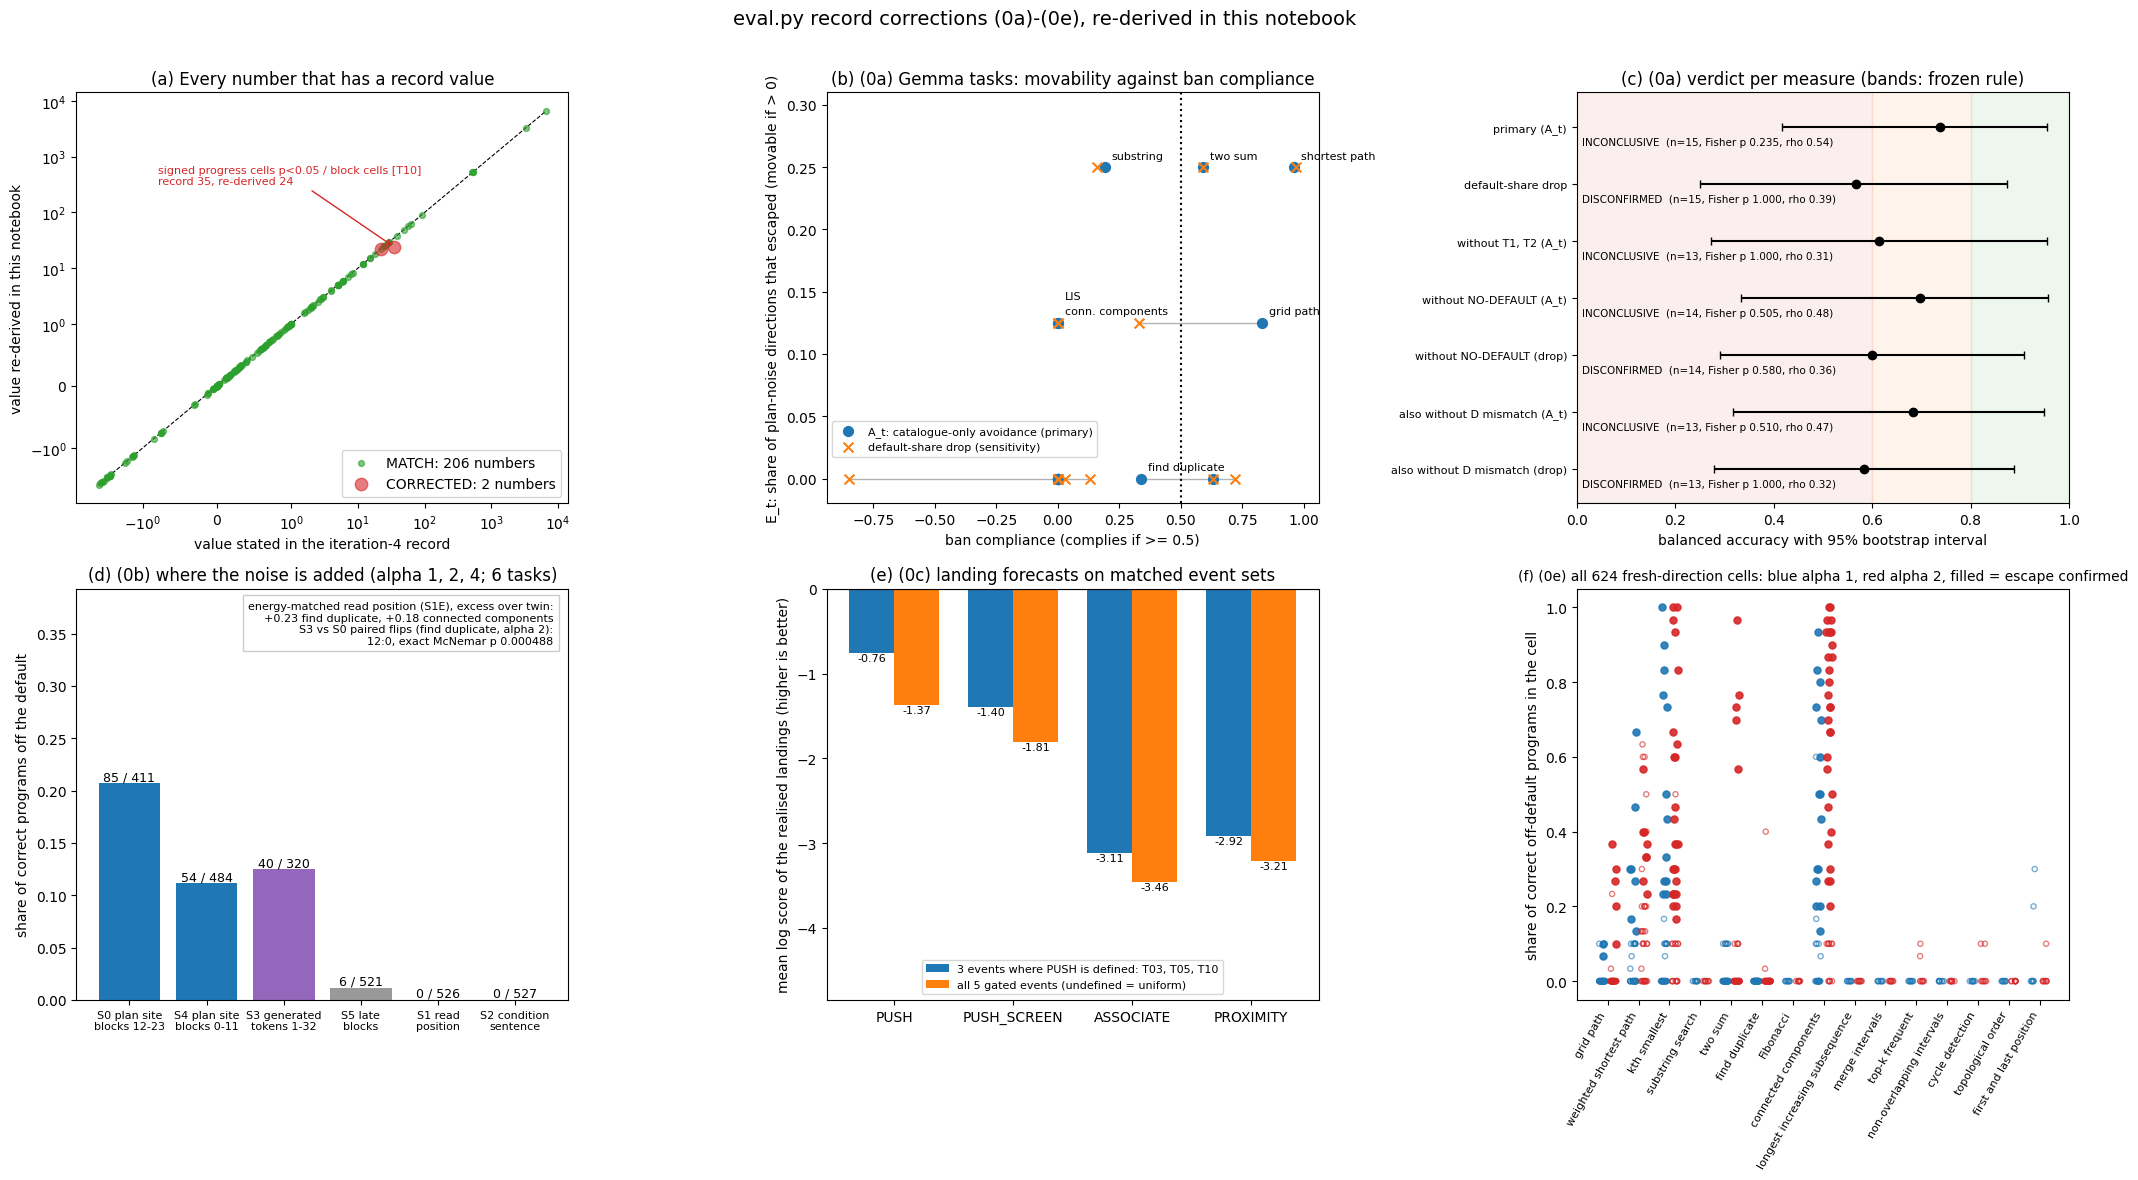

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
fig.suptitle("eval.py record corrections (0a)-(0e), re-derived in this notebook", fontsize=14)
isnum = lambda z: isinstance(z, (int, float)) and not isinstance(z, bool)  # noqa: E731

# (a) every number that has a record value: re-derived (y) against the iteration-4 record (x)
ax = axes[0, 0]
pts = []
for v in allv:
    a_, b_ = v.get("value"), v.get("record_value")
    if isnum(a_) and isnum(b_):
        pts.append((b_, a_, v["status"], v["name"]))
    elif isinstance(a_, (list, tuple)) and isinstance(b_, (list, tuple)) and len(a_) == len(b_) \
            and all(isnum(z) for z in list(a_) + list(b_)):
        pts += [(y_, x_, v["status"], v["name"]) for x_, y_ in zip(a_, b_)]
for st, col, size in (("MATCH", "tab:green", 18), ("CORRECTED", "tab:red", 80)):
    sel = [p for p in pts if p[2] == st]
    ax.scatter([p[0] for p in sel], [p[1] for p in sel], s=size, c=col, alpha=0.6, zorder=3,
               label=f"{st}: {len(sel)} numbers")
lo, hi = min(min(p[0], p[1]) for p in pts), max(max(p[0], p[1]) for p in pts)
ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, zorder=1)
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("symlog", linthresh=1)
for k, p in enumerate([p for p in pts if p[2] == "CORRECTED" and p[0] != p[1]]):
    ax.annotate(f"{p[3]}\nrecord {p[0]:g}, re-derived {p[1]:g}", (p[0], p[1]), xytext=(-170, 45 + 32 * k),
                textcoords="offset points", fontsize=8, color="tab:red",
                arrowprops=dict(arrowstyle="->", color="tab:red"))
ax.set_xlabel("value stated in the iteration-4 record")
ax.set_ylabel("value re-derived in this notebook")
ax.set_title("(a) Every number that has a record value")
ax.legend(loc="lower right")

# (b) (0a) per Gemma task: movability E_t against the two compliance measures
ax = axes[0, 1]
pt0a = METRICS["0a"]["per_task"]
for t, v in pt0a.items():
    ax.plot([v["A_catalogue_only"], v["default_share_drop"]], [v["E_t"]] * 2, c="0.7", lw=1, zorder=1)
ax.scatter([v["A_catalogue_only"] for v in pt0a.values()], [v["E_t"] for v in pt0a.values()], s=50, c="tab:blue",
           zorder=3, label="A_t: catalogue-only avoidance (primary)")
ax.scatter([v["default_share_drop"] for v in pt0a.values()], [v["E_t"] for v in pt0a.values()], s=50, c="tab:orange",
           marker="x", zorder=3, label="default-share drop (sensitivity)")
short_name = {"T1": "grid path", "T2": "shortest path", "T03": "kth smallest", "T04": "substring", "T05": "two sum",
              "T06": "find duplicate", "T10": "conn. components", "T11": "LIS"}
stack = Counter()  # stagger the labels of tasks that share a point
for t, v in sorted(pt0a.items(), key=lambda kv: kv[1]["A_catalogue_only"]):
    if v["E_t"] > 0 or t in ("T1", "T06"):
        key_ = (round(v["A_catalogue_only"], 2), round(v["E_t"], 3))
        ax.annotate(short_name.get(t, NAMES.get(t, t)), (v["A_catalogue_only"], v["E_t"]),
                    xytext=(5, 6 + 11 * stack[key_]), textcoords="offset points", fontsize=8)
        stack[key_] += 1
ax.axvline(0.5, ls=":", c="k")
ax.set_ylim(-0.02, max(v["E_t"] for v in pt0a.values()) + 0.06)
ax.set_xlabel("ban compliance (complies if >= 0.5)")
ax.set_ylabel("E_t: share of plan-noise directions that escaped (movable if > 0)")
ax.set_title("(b) (0a) Gemma tasks: movability against ban compliance")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.1), fontsize=8)

# (c) (0a) balanced accuracy per variant on the frozen verdict bands
ax = axes[0, 2]
short = ["primary (A_t)", "default-share drop", "without T1, T2 (A_t)", "without NO-DEFAULT (A_t)",
         "without NO-DEFAULT (drop)", "also without D mismatch (A_t)", "also without D mismatch (drop)"]
vs0a = METRICS["0a"]["variants"]
for b_lo, b_hi, col in ((0, 0.6, "tab:red"), (0.6, 0.8, "tab:orange"), (0.8, 1.0, "tab:green")):
    ax.axvspan(b_lo, b_hi, color=col, alpha=0.08)
for i, v in enumerate(vs0a):
    if v["BA"] is None:
        continue
    cl, ch = v["BA_ci95"] or [v["BA"], v["BA"]]
    ax.errorbar(v["BA"], i, xerr=[[max(0, v["BA"] - cl)], [max(0, ch - v["BA"])]], fmt="o", c="k", capsize=3)
    ax.text(0.01, i + 0.32, f"{v['verdict_frozen_rule']}  (n={v['n_tasks']}, Fisher p "
            f"{fmt(v['fisher_p_two_sided'], 3)}, rho {fmt(v['spearman_rho'])})", fontsize=7.5)
ax.set_yticks(range(len(vs0a)))
ax.set_yticklabels(short[:len(vs0a)], fontsize=8)
ax.set_ylim(len(vs0a) - 0.4, -0.6)
ax.set_xlim(0, 1)
ax.set_xlabel("balanced accuracy with 95% bootstrap interval")
ax.set_title("(c) (0a) verdict per measure (bands: frozen rule)")

# (d) (0b) correct programs off the default, by noise site
ax = axes[1, 0]
order = ["S0", "S4", "S3", "S5", "S1", "S2"]
site_lab = {"S0": "S0 plan site\nblocks 12-23", "S4": "S4 plan site\nblocks 0-11", "S3": "S3 generated\ntokens 1-32",
            "S5": "S5 late\nblocks", "S1": "S1 read\nposition", "S2": "S2 condition\nsentence"}
shares = [sc0b[s]["n_correct_off_default"] / sc0b[s]["n_correct"] if sc0b[s]["n_correct"] else 0.0 for s in order]
ax.bar(range(len(order)), shares, color=["tab:blue", "tab:blue", "tab:purple", "0.6", "0.6", "0.6"])
for i, s in enumerate(order):
    ax.text(i, shares[i], f"{sc0b[s]['n_correct_off_default']} / {sc0b[s]['n_correct']}", ha="center", va="bottom",
            fontsize=9)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([site_lab[s] for s in order], fontsize=8)
ax.set_ylim(0, max(shares) * 1.9 if max(shares) > 0 else 1)
ax.set_ylabel("share of correct programs off the default")
f2 = fl0b["T06|2|attempts"]
ax.text(0.97, 0.97, f"energy-matched read position (S1E), excess over twin:\n"
        f"{em0b['S1E|T06']['excess']:+.2f} find duplicate, {em0b['S1E|T10']['excess']:+.2f} connected components\n"
        f"S3 vs S0 paired flips (find duplicate, alpha 2):\n{f2['S3_only']}:{f2['S0_only']}, exact McNemar p "
        f"{f2['mcnemar_p_exact']:.6f}", transform=ax.transAxes, ha="right", va="top", fontsize=8,
        bbox=dict(fc="white", ec="0.8"))
ax.set_title("(d) (0b) where the noise is added (alpha 1, 2, 4; 6 tasks)")

# (e) (0c) landing log scores on matched event sets
ax = axes[1, 1]
tab0c = {row["forecast"]: row for row in METRICS["0c"]["table"]}
fams = [f for f in ("PUSH", "PUSH_SCREEN", "ASSOCIATE", "PROXIMITY") if f in tab0c]
xpos, w = np.arange(len(fams)), 0.38
lowest = 0.0
for off_, key, lab_ in ((-w / 2, "mean_bench_push_defined",
                         "3 events where PUSH is defined: " + ", ".join(METRICS["0c"]["sets"]["push_defined"])),
                        (w / 2, "mean_bench_all_gated_uniform_fill", "all 5 gated events (undefined = uniform)")):
    ys = [tab0c[f][key] if tab0c[f][key] is not None else np.nan for f in fams]
    ax.bar(xpos + off_, ys, w, label=lab_)
    for xx, yy in zip(xpos + off_, ys):
        if not np.isnan(yy):
            ax.text(xx, yy, f"{yy:.2f}", ha="center", va="top", fontsize=8)
            lowest = min(lowest, yy)
ax.axhline(0, c="k", lw=0.8)
ax.set_ylim(lowest * 1.4, 0)
ax.set_xticks(xpos)
ax.set_xticklabels(fams)
ax.set_ylabel("mean log score of the realised landings (higher is better)")
ax.set_title("(e) (0c) landing forecasts on matched event sets")
ax.legend(loc="lower center", fontsize=8)

# (f) (0e) the full per-direction distribution instead of the best cell
ax = axes[1, 2]
dd = pd.read_csv(TABLES / "direction_distributions.csv")
order_t = [t for t in TASKS if t in set(dd["task"])]
jit = np.random.default_rng(0)  # horizontal jitter for the plot only
for j, t in enumerate(order_t):
    for a_, col, dx in ((1.0, "tab:blue", -0.18), (2.0, "tab:red", 0.18)):
        sub = dd[(dd["task"] == t) & (dd["alpha"] == a_)]
        xs = j + dx + jit.uniform(-0.1, 0.1, len(sub))
        escm = (sub["escape_confirmed"].astype(str) == "True").to_numpy()
        ys = sub["correct_off_default_share"].to_numpy()
        ax.scatter(xs[~escm], ys[~escm], s=14, facecolors="none", edgecolors=col, alpha=0.6)
        ax.scatter(xs[escm], ys[escm], s=26, c=col, alpha=0.9)
ax.set_xticks(range(len(order_t)))
ax.set_xticklabels([NAMES.get(t, t) for t in order_t], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("share of correct off-default programs in the cell")
ax.set_title(f"(f) (0e) all {len(dd)} fresh-direction cells: blue alpha 1, red alpha 2, filled = escape confirmed",
             fontsize=10)

plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## Notes

- **Full pipeline:** this needs the artifact repository and the eight dependency folders (see its `README.md` / `reproducibility.md`). Run `python rivals/r6_merit.py`, then `python rivals/r5_human.py`, then `python eval.py`. It also freezes and scores the rivals, re-verifies the quotes live, runs the audit and writes `eval_out.json`.
- **Rival predictors (0i):** not part of the corrections stage. They are frozen and scored by `rivals/compute_rivals.py` and `rivals/score_rivals.py`. Their descriptive Spearman correlations with E_pool, as reported in the artifact's `eval_out.json` (not re-computed here), are K +0.46, R5 +0.39, R4 +0.38, R2 +0.30, R8 +0.21, R6 +0.14, R7 −0.16, R3 −0.16, R1 −0.33. Every Holm p is 1.0, and 10 of 15 tasks sit at E_pool = 0.
- **Data:** `mini_demo_data.json` is rebuilt from the dependency files by `build_mini_demo_data.py` in the demo folder. It checks every source file against the sha256 the artifact recorded.